# 02_curvature — 판정 코드 검산, 곡률 입력 준비, 사전 고정 (S3 1부, 0S-3)

S3 1부다. **실데이터 그래프의 κ·κ_geo는 계산하지 않는다**(`RUN_REAL_CURVATURE = False`). ADR 0013 7항에 따라 이 노트북과 산출물을 고정 커밋한 뒤, 2부에서 이 플래그만 True로 바꿔 실행한다.

- 1절: 판정 계산 코드(`curvature_lib.py`)를 합성 그래프로 검산한다. PLAN 7.1 fixture와 다리 길이 barbell을 1e-9 이내로 재현하고, 통계 함수와 판정 함수를 점검한다. 하나라도 실패하면 이 노트북은 거기서 멈춘다.
- 2절: 입력 준비(곡률 계산 아님). `G_adj` 250개 단위와 249개 단위, 엣지 속성, 섬 링크 ×0.5·×2 행렬, DEM 경사, 백두대간 선, 노드 매칭 점검. 결과는 `g_adj_edges.csv`, `g_adj249_edges.csv`, `bridges.csv`, `node_matching.csv`, `s3_freeze.json`에 남긴다.
- 3절: 실데이터 곡률·검정·보조 보고·지도·판정. 코드만 있고 건너뛴다. 합성 장난감 나라에서 배선만 점검했다(실데이터 값 아님).

실행 환경은 `C:\dev\kfm-spike`, 실행은 `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600`이다(약 2분). 0S 탐색 코드라서 `kfm` 패키지·`runs`·스키마 규칙 밖이다(PLAN 6.1a).

## 판정 규칙 요약 (ADR 0013, 2026-10-19 18:17 KST 개정)
- 결과 변수 κ_ex = κ(`d_sym`) − κ_geo. 대상은 경계 공유 엣지만(연륙·연도교와 섬 링크는 그래프에 두고 검정에서 뺀다). 지형 지표는 선분 평균 경사 s.
- 주 검정: 단측 Spearman ρ(κ_ex, s) > 0. 편상관 검정: 우회율 r = `d_sym` / 직선 거리를 통제한 편 Spearman. 두 검정 모두 단순 p와 시도 jackknife 최대 p가 0.05 미만이면 통과.
- 유효성 점검: κ_ex와 (1/deg_u + 1/deg_v), 해안·접경 지시변수, log 직선 거리의 |ρ| < 0.1.
- 판정(5항): 조정 → 계속 → 전제 재검토 → 부분 대응 순서로 처음 해당하는 하나. 수치가 빠지면 미완.

## 산맥 선 출처 (ADR 0013 6항)
- **백두대간 선**: 공공데이터포털 「한국등산트레킹지원센터_백두대간 종주길_20220112」(데이터 번호 15098180, GPX, 7개 산권 52코스, 이용허락범위 제한 없음). 2026-10-19에 로그인 없이 받았고 `C:\dev\kfm-data\raw\baekdudaegan_gpx_20261019\`에 두었다(MD5와 출처는 `manifest.csv`). 산권 순서(지리산 → 덕유산 → 속리산 → 소백산 → 태백산 → 오대산 → 설악산)와 산권 안 코스 번호 순으로 잇고, 각 코스는 앞 코스 끝점에 가까운 끝부터 잇고, 틈은 직선으로 잇는다.
- **GPX 연결 결과**(아래 첫 코드 셀이 같은 값을 다시 계산해 일치를 확인한다): 코스 52개 모두 있음(빠진 코스 없음), 틈 51개, 최대 틈 3,880 m(속리산권 6→7코스), 1 km 넘는 틈 2개(속리산권 6→7 3,880 m, 덕유산권 3→4 1,872 m), 틈 길이 합 7.52 km, 이어 붙인 선 길이 694.57 km, 코스 트랙 점 길이의 합 687.05 km. **GPX 안에는 코스별 거리 값이 없다**(metadata·name·desc가 비어 있음)라서 "GPX에 적힌 코스 거리의 합"은 낼 수 없고, 트랙 점으로 계산한 길이의 합을 대신 쓴다. 1 km 넘는 틈 2개를 포함해 **직선으로 이은 선 그대로 고정한다**(아래 해석 3).
- **민감도 선**: 백두대간 선에 OSM(Geofabrik 2026-10-17 PBF)의 이름에 "정맥"이 든 `route=hiking` 관계 8개(낙동·낙남·호남·금남호남·금남·금북·한남금북·한북정맥)의 도로·길 way를 더한 선. 한남정맥은 OSM에 없다. 손으로 따지 않았다.
- 진단용: OSM 백두대간 관계(`relation 9439787`)와 GPX 선의 거리 비교, 그리고 틈 구간을 OSM 선으로 대신했을 때 교차 여부가 달라지는 엣지 수를 2절에서 보고한다(판정에는 쓰지 않는다).

## 구현에서 정한 해석 (지시·ADR에 문구가 없어 이 노트북이 정한 것, 고정 전 검토에서 승인된 것)
1. 연륙·연도교 탐지: 지시 원문 규칙(한 way 안에서 라벨이 바뀌는 곳, 규칙 A)에 **way를 넘는 바다 위 덩어리 규칙(규칙 B)을 더했다**(B 유지 승인). A만으로는 바다 위 노드만 있는 다리·터널 way가 따로 매핑된 거가대로(거제–부산 강서), 원산안면대교(보령–태안), 진도대교 구간(해남–진도)이 빠진다. 설정 `bridge_rule`로 끌 수 있다.
2. **바다 횡단 조건**(승인): 모든 후보(규칙 A, B)는 두 육지 라벨 사이에 지역 다각형 합집합 밖(바다)에 있는 노드가 하나 이상 있거나, 라벨이 붙은 이웃 노드 사이 선분이 합집합 밖을 지나야 한다. 바다를 지나지 않는 육지 터널은 빠진다(대구 수성–달서 앞산터널: `tunnel=yes`, 연결 선분 1,943 m 전체가 합집합 안). 규칙 B 후보는 정의상 바다 위 노드를 지난다. **보정 하나**: 부산 중구–영도(영도대교)는 폴리곤이 해협을 덮어(두 구가 47 m 접촉하고 연결 선분 25 m·110 m가 합집합 안) 이 조건만으로는 빠지므로, way에 `bridge` 태그가 있고 `tunnel` 태그가 없으면 바다 횡단으로 본다(설정 `bridge_tag_fallback`, 끄면 영도대교도 빠진다). 결과는 후보 23쌍 -> 22쌍이고 빠진 쌍은 앞산터널 하나다(2-2의 출력).
3. GPX에서 1 km를 넘는 틈 2개(속리산권 6→7코스 3,880 m, 덕유산권 3→4코스 1,872 m)는 **직선으로 이은 선 그대로 고정한다**(승인). 틈을 OSM 백두대간 선으로 바꿔도 교차 엣지 30개가 같다(2-8의 진단).
4. 다음 세 가지는 이 해석대로 승인됐다. (a) 상위 20개의 모집단은 검정 대상인 경계 공유 엣지다. (b) 해안·접경 지시변수는 지역 다각형 합집합의 **바깥 경계**(구멍 15개는 제외, 구멍에는 호수와 다각형 사이 틈이 섞여 있다)에 닿는 지역이면 1이다. (c) 노드 매칭 **오류** = 연결선 > 5 km 또는 연결된 노드가 자기 시군구 밖이다. 가장 가까운 노드가 작은 도로 조각이라 최대 성분의 더 먼 노드로 옮겨진 경우는 목록에만 올리고 오류로 세지 않는다.
5. 249개 단위: 합친 노드의 위치(직선 거리·경사·산맥 선 교차에 씀)는 두 출발점의 인구 가중 평균점.
6. 5분류의 "망 단절"은 경계 공유 엣지 r(= `d_sym` / 직선 km)의 90분위수 이상. "자연 장벽"은 백두대간 선(GPX)과 교차하는 엣지.
7. 섬 링크 민감도에서 "자기 κ_ex가 기준 20위 값보다 작아진다"는 1e-9 이상 작아진 경우만 센다(부동소수점 잡음 방지). 섬 링크와 무관한 엣지의 ×0.5·×2 `d_sym`은 기준 값으로 맞춘다(재계산 잡음 1e-13 제거).
8. 첫 GPX 코스(지리산권 1코스)는 다음 코스에 가까운 쪽이 끝이 되게 놓는다(실제로는 뒤집지 않았다).

In [1]:
# 02_curvature 설정 셀 (S3 1부): 경로, 설정값, 자료 MD5 점검, GPX 연결 결과
import csv
import datetime
import hashlib
import importlib.metadata as md
import io
import json
import platform
import re
import sys
import time
import warnings
import xml.etree.ElementTree as ET
import zipfile
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyproj
import shapely
from shapely import STRtree

import curvature_lib as cl

RUN_REAL_CURVATURE = True  # 3절(실데이터 곡률)을 돌릴지. 2부에서 이 값만 True로 바꿔 실행한다.

T_START = time.time()
RAW = Path(r"C:\dev\kfm-data\raw")
DATA = Path(r"C:\dev\kfm-data\spike")
NB_DIR = Path.cwd()  # notebooks/spike (nbconvert는 노트북 폴더에서 실행한다)
assert (NB_DIR / "curvature_lib.py").exists(), "notebooks/spike 폴더에서 실행해야 한다"
assert "kfm-spike" in sys.executable, "커널이 kfm-spike 환경이 아니다"
CRS_WORK = "EPSG:5179"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 설정값(고정 대상, ADR 0013): 값을 바꾸면 s3_freeze.json과 달라져 2절이 멈춘다
CONFIG = {
    "alpha": 0.5,                      # 게으른 측도의 중심 질량
    "min_shared_boundary_m": 50.0,     # 경계 공유 문턱(점 접촉 제외)
    "p_threshold": 0.05,
    "validity_threshold": 0.1,
    "n_jackknife_groups": 17,          # 시도(2025-12-31 경계)
    "top_k": 20,
    "data_problem_majority": 11,
    "connector_long_m": 5000.0,        # 데이터·설정 문제: 연결선 > 5 km
    "dem": {"source": "Copernicus GLO-90 (35 tiles)", "block_m": 250.0, "block_resampling": "average (GDAL warp, EPSG:4326 -> EPSG:5179)",
            "grid_margin_m": 5000.0, "slope_step_m": 250.0, "slope_lookup": "nearest 250 m cell", "sea_mask": "outside union of region polygons",
            "nodata_fill": "linear interpolation along the segment", "slope_formula": "sum|dz| / 2 / length_km (m/km)",
            "he_step_m": 100.0, "he_lookup": "nearest 90 m pixel", "he_formula": "max elevation on segment - max(endpoint elevations)"},
    "island_factors": [0.5, 2.0],
    "bridge_rule": "within_way + chain",  # 지시 원문 규칙(A)에 way를 넘는 바다 위 덩어리 규칙(B)을 더함
    "bridge_sea_condition": "candidate needs >= 1 unlabeled (outside region union) node between the two land labels, or the segment between neighbouring labeled nodes passes outside the union",
    "bridge_tag_fallback": True,       # 폴리곤이 해협을 덮어 위 판정이 실패한 후보라도 way에 bridge 태그가 있고 tunnel 태그가 없으면 바다 횡단으로 본다(영도대교)
    "coastal_outline": "exterior rings of union of region polygons (holes excluded)",
    "od": {"flow": "T_xz + T_zx (zone-internal excluded)", "zero_flow_epsilon_persons": 1.0, "merged_units": "창원 의창구(48121)+성산구(48123) -> 249 units",
           "merged_d_sym": "population-weighted mean of sub-region pair d_sym (pop_2025_12)", "merged_position": "population-weighted mean of sub-origins"},
    "node_matching": {"error": "connector > 5 km or connected node outside own sigungu polygon", "note_only": "nearest node not in main component"},
}


def md5_file(path, block=1 << 22):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()


def emit_bytes(path, data):
    """처음이면 쓰고, 이미 있으면 내용이 같은지 확인한다(고정 뒤에는 바뀌면 안 된다)."""
    path = Path(path)
    if path.exists():
        if path.read_bytes() != data:
            raise RuntimeError(f"{path.name}: 고정된 파일과 내용이 다르다. 의도한 변경이면 파일을 지우고 다시 실행한다")
        print(f"  검증: {path.name} (기존 파일과 같다)")
    else:
        path.write_bytes(data)
        print(f"  저장: {path.name} ({len(data):,} bytes)")


def emit_csv(path, df):
    emit_bytes(path, df.to_csv(index=False, lineterminator="\n").encode("utf-8-sig"))


print("실행 시각:", datetime.datetime.now().isoformat(timespec="seconds"), "| python", sys.version.split()[0], "|", platform.platform())
print("실행 파일:", sys.executable, "| RUN_REAL_CURVATURE =", RUN_REAL_CURVATURE)
for pkg in ["numpy", "scipy", "pandas", "pyarrow", "geopandas", "shapely", "pyproj", "rasterio", "POT", "duckdb", "matplotlib"]:
    print(f"  {pkg:11s}{md.version(pkg)}")

# --- 원자료 MD5 점검(manifest 기준)
manifest = pd.read_csv(RAW / "manifest.csv", encoding="utf-8-sig", dtype=str)
mf = manifest.set_index("path")
RAW_USED = {
    "pbf": "geofabrik_20261018/south-korea-261017.osm.pbf",
    "od": "kosis_DT_1PA2021_20261018/f_89098_101_DT_1PA2021_F_2020.csv",
    "gpx_zip": "baekdudaegan_gpx_20261019/kmtsc_baekdudaegan_gpx_20220112.zip",
}
dem_paths = sorted((RAW / "copernicus_dem90_20261019").glob("*.tif"))
assert len(dem_paths) == 35
MD5 = {}
for k, rel in RAW_USED.items():
    MD5[k] = md5_file(RAW / rel)
    assert MD5[k] == mf.loc[rel, "md5"], f"{rel}: manifest MD5와 다르다"
DEM_MD5 = {p.name: md5_file(p) for p in dem_paths}
for p in dem_paths:
    assert DEM_MD5[p.name] == mf.loc["copernicus_dem90_20261019/" + p.name, "md5"], p.name
print(f"원자료 MD5 일치(manifest): PBF, 통근·통학 OD, 백두대간 GPX zip, DEM 타일 {len(dem_paths)}개")

# --- 백두대간 GPX 연결(ADR 0013 6항)
TR_5179 = pyproj.Transformer.from_crs("EPSG:4326", CRS_WORK, always_xy=True)
gpx_courses = []
with zipfile.ZipFile(RAW / RAW_USED["gpx_zip"]) as zf:
    for info in zf.infolist():
        if info.is_dir():
            continue
        name = info.filename if (info.flag_bits & 0x800) else info.filename.encode("cp437").decode("cp949")
        m = re.match(r"^(\d+)\.백두대간 (\S+) 종주/.*_(\d+)코스", name)
        assert m, name
        root = ET.fromstring(zf.read(info))
        pts = [(float(p.get("lon")), float(p.get("lat"))) for p in root.iter("{http://www.topografix.com/GPX/1/1}trkpt")]
        assert len(pts) >= 2
        x, y = TR_5179.transform([p[0] for p in pts], [p[1] for p in pts])
        gpx_courses.append(((int(m.group(1)), int(m.group(3))), f"{m.group(2)} {int(m.group(3))}코스", np.c_[x, y]))
EXPECT_COURSES = {1: 7, 2: 8, 3: 8, 4: 7, 5: 8, 6: 6, 7: 8}  # 포털 설명의 산권별 코스 수
got = pd.Series([k[0] for k, _, _ in gpx_courses]).value_counts().sort_index().to_dict()
assert got == EXPECT_COURSES, got
GPX = cl.connect_courses(gpx_courses)
BAEKDU_LINE = GPX["line"]
gaps = sorted(GPX["gaps"], key=lambda g: -g["length_m"])
n_gap_gt1km = sum(g["length_m"] > 1000 for g in gaps)
print(f"\n[백두대간 GPX 연결] 코스 {len(gpx_courses)}개(산권별 {got}, 빠진 코스 없음), 틈 {len(gaps)}개, 최대 틈 {gaps[0]['length_m']:,.0f} m "
      f"({gaps[0]['after']} -> {gaps[0]['before']}), 1 km 넘는 틈 {n_gap_gt1km}개, 틈 합 {GPX['gap_total_m'] / 1000:.2f} km")
print(f"  이어 붙인 선 {GPX['line_len_m'] / 1000:.2f} km, 코스 트랙 점 길이의 합 {GPX['course_len_sum_m'] / 1000:.2f} km (GPX에는 코스 거리 값이 없다), 뒤집어 이은 코스 {sum(r for _, r in GPX['order'])}개")
print("  상위 틈:", [(g["after"], g["before"], round(g["length_m"])) for g in gaps[:4]])
STATED = {"n_gaps": 51, "max_gap_m": 3880, "n_gap_gt1km": 2, "gap_total_km": 7.52, "line_km": 694.57, "course_sum_km": 687.05}
CALC = {"n_gaps": len(gaps), "max_gap_m": round(gaps[0]["length_m"]), "n_gap_gt1km": n_gap_gt1km, "gap_total_km": round(GPX["gap_total_m"] / 1000, 2),
        "line_km": round(GPX["line_len_m"] / 1000, 2), "course_sum_km": round(GPX["course_len_sum_m"] / 1000, 2)}
assert CALC == STATED, f"첫 셀(마크다운)에 적은 GPX 연결 결과와 다르다: {CALC} vs {STATED}"
print("  첫 마크다운 셀에 적은 값과 일치")

실행 시각: 2026-10-19T19:42:03 | python 3.11.9 | Windows-10-10.0.26200-SP0
실행 파일: C:\dev\kfm-spike\.venv\Scripts\python.exe | RUN_REAL_CURVATURE = True
  numpy      2.4.6
  scipy      1.17.1
  pandas     3.0.6
  pyarrow    26.0.0
  geopandas  1.2.0
  shapely    2.2.0
  pyproj     3.7.2
  rasterio   1.4.4
  POT        0.9.7.post1
  duckdb     1.5.6
  matplotlib 3.11.2


원자료 MD5 일치(manifest): PBF, 통근·통학 OD, 백두대간 GPX zip, DEM 타일 35개

[백두대간 GPX 연결] 코스 52개(산권별 {1: 7, 2: 8, 3: 8, 4: 7, 5: 8, 6: 6, 7: 8}, 빠진 코스 없음), 틈 51개, 최대 틈 3,880 m (속리산권 6코스 -> 속리산권 7코스), 1 km 넘는 틈 2개, 틈 합 7.52 km
  이어 붙인 선 694.57 km, 코스 트랙 점 길이의 합 687.05 km (GPX에는 코스 거리 값이 없다), 뒤집어 이은 코스 0개
  상위 틈: [('속리산권 6코스', '속리산권 7코스', 3880), ('덕유산권 3코스', '덕유산권 4코스', 1872), ('설악산권 4코스', '설악산권 5코스', 849), ('속리산권 1코스', '속리산권 2코스', 174)]
  첫 마크다운 셀에 적은 값과 일치


## 1. 판정 코드 합성 검산 (실행 결과를 남긴다)

PLAN 7.1: 엣지 길이 1, 균등 분포, α = 0.5. 허용오차 1e-9. 하나라도 실패하면 `assert`가 멈춘다(실데이터 단계로 가지 않는다).

In [2]:
# 1-1. ORC fixture (PLAN 7.1 barbell, cycle, complete + ADR 0013 다리 길이 barbell)
TOL = 1e-9
SYNTH = {"tolerance": TOL, "orc": {}, "stats": {}, "decision": {}, "helpers": {}}
rows = []


def check(name, got, expect, record=True):
    err = float(np.max(np.abs(np.asarray(got, float) - np.asarray(expect, float))))
    assert err < TOL, f"{name}: 최대 오차 {err:.3e}"
    if record:
        rows.append((name, err, "OK"))
    return err


n, u, v, ln = cl.graph_barbell(1.0)
k = cl.orc(n, u, v, ln, 0.5)
bridge = len(u) - 1
near = np.array([e for e in range(bridge) if (u[e] in (0, 5) or v[e] in (0, 5))])
far = np.array([e for e in range(bridge) if e not in set(near)])
assert len(near) == 8 and len(far) == 12
check("barbell 다리 = -0.6", k[bridge], -0.6)
assert int(np.argmin(k)) == bridge and int((k < k[bridge] + 1e-9).sum()) == 1, "다리가 유일한 최솟값이 아니다"
check("barbell 다리 끝점 쪽 8개 = 0.425", k[near], 0.425)
check("barbell 나머지 12개 = 0.625", k[far], 0.625)
SYNTH["orc"]["barbell_bridge_is_unique_min"] = True
k_lp = cl.orc_lp(n, u, v, ln, 0.5)  # W1을 선형계획으로 푼 독립 검산
SYNTH["orc"]["emd2_vs_linprog_barbell_max_abs_diff"] = float(np.abs(k - k_lp).max())
check("barbell 21개 엣지: ot.emd2 vs 선형계획(HiGHS)", k, k_lp)

n8, u8, v8, l8 = cl.graph_cycle(8)
check("C8 모든 엣지 = 0", cl.orc(n8, u8, v8, l8, 0.5), 0.0)
n5, u5, v5, l5 = cl.graph_cycle(5)
check("C5 모든 엣지 = 0.25", cl.orc(n5, u5, v5, l5, 0.5), 0.25)

worst_kn = 0.0
for kk in (3, 4, 5, 6, 8, 10):
    nk, uk, vk, lk = cl.graph_complete(kk)
    for a in (0.0, 0.25, 0.5, 0.75, 1.0):
        worst_kn = max(worst_kn, check(f"K{kk} α={a}", cl.orc(nk, uk, vk, lk, a), 1 - abs(a - (1 - a) / (kk - 1)), record=False))
rows.append(("K_n (n=3,4,5,6,8,10) x α (0,.25,.5,.75,1) 30칸: κ = 1 - |α - (1-α)/(n-1)|", worst_kn, "OK"))

worst_len = 0.0
for L in (1, 2, 4, 8, 32):
    nb_, ub, vb, lb = cl.graph_barbell(float(L))
    kb = cl.orc(nb_, ub, vb, lb, 0.5)
    worst_len = max(worst_len, check(f"barbell L={L}", kb[-1], 0.2 - 0.8 / L, record=False))
rows.append(("barbell 다리 길이 L=1,2,4,8,32: κ = 0.2 - 0.8/L", worst_len, "OK"))
SYNTH["orc"].update({"barbell_bridge": -0.6, "barbell_near8": 0.425, "barbell_far12": 0.625, "C8": 0.0, "C5": 0.25,
                     "Kn_max_abs_err": worst_kn, "bridge_length_L_1_2_4_8_32": [-0.6, -0.2, 0.0, 0.1, 0.175], "bridge_length_max_abs_err": worst_len})
print(pd.DataFrame(rows, columns=["검산", "최대 오차", "결과"]).to_string(index=False, formatters={"최대 오차": "{:.2e}".format}))
print("다리 길이 barbell κ:", {L: round(float(cl.orc(*cl.graph_barbell(float(L)), 0.5)[-1]), 6) for L in (1, 2, 4, 8, 32)})

                                                                      검산    최대 오차 결과
                                                       barbell 다리 = -0.6 3.33e-16 OK
                                              barbell 다리 끝점 쪽 8개 = 0.425 5.00e-16 OK
                                                 barbell 나머지 12개 = 0.625 0.00e+00 OK
                                  barbell 21개 엣지: ot.emd2 vs 선형계획(HiGHS) 4.44e-16 OK
                                                            C8 모든 엣지 = 0 0.00e+00 OK
                                                         C5 모든 엣지 = 0.25 0.00e+00 OK
K_n (n=3,4,5,6,8,10) x α (0,.25,.5,.75,1) 30칸: κ = 1 - |α - (1-α)/(n-1)| 1.11e-16 OK
                             barbell 다리 길이 L=1,2,4,8,32: κ = 0.2 - 0.8/L 4.44e-16 OK
다리 길이 barbell κ: {1: -0.6, 2: -0.2, 4: 0.0, 8: 0.1, 32: 0.175}


In [3]:
# 1-2. 통계 함수: 편 Spearman을 독립 계산과 비교, jackknife 장난감 예제
from scipy import special, stats

rng = np.random.default_rng(1)
n_ = 120
z_ = rng.normal(size=n_)
x_ = z_ + 0.7 * rng.normal(size=n_)
y_ = 0.5 * z_ + 0.4 * x_ + rng.normal(size=n_)
rho_c, p_c = cl.partial_spearman_greater(x_, y_, z_)
rxy, rxz, ryz = (stats.spearmanr(a, b).statistic for a, b in ((x_, y_), (x_, z_), (y_, z_)))
rho_f = (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))          # 1차 편상관 공식
prec = np.linalg.inv(np.corrcoef(np.vstack([stats.rankdata(a) for a in (x_, y_, z_)])))
rho_p = -prec[0, 1] / np.sqrt(prec[0, 0] * prec[1, 1])                          # 정밀도 행렬 경로
t_ = rho_f * np.sqrt((n_ - 3) / (1 - rho_f ** 2))
df_ = n_ - 3
p_b = 0.5 * special.betainc(df_ / 2, 0.5, df_ / (df_ + t_ ** 2))               # t 분포를 쓰지 않는 베타 함수 경로(t > 0)
d_rho = max(abs(rho_c - rho_f), abs(rho_c - rho_p))
d_p = abs(p_c - p_b)
assert d_rho < TOL and d_p < TOL and t_ > 0
# 알려진 답: x, y가 모두 z에서 나오고 직접 관계가 없으면 편상관은 0 근처, 단순 상관은 큼
zz = rng.normal(size=400)
xx, yy = zz + 0.5 * rng.normal(size=400), zz + 0.5 * rng.normal(size=400)
raw_ = cl.spearman_greater(xx, yy)
par_ = cl.partial_spearman_greater(xx, yy, zz)
assert raw_[0] > 0.7 and abs(par_[0]) < 0.15
print(f"편 Spearman: 구현 {rho_c:.12f} | 1차 공식 {rho_f:.12f} | 정밀도 행렬 {rho_p:.12f} (최대 차 {d_rho:.1e}); 단측 p 구현 {p_c:.6e} vs 베타 함수 {p_b:.6e} (차 {d_p:.1e})")
print(f"알려진 답(공통 원인): 단순 ρ {raw_[0]:.3f} (p {raw_[1]:.1e}), 편 ρ {par_[0]:.3f} (p {par_[1]:.3f})")

# jackknife 장난감: 신호가 시도 0에 닿는 엣지에만 있다 -> 단순 p는 작고, jackknife 최대 p는 시도 0을 뺀 값이어야 한다
m_ = 60
su_ = np.repeat([0, 1, 2], 20)
sv_ = su_.copy()
sv_[::5] = (sv_[::5] + 1) % 3  # 12개는 끝점 시도가 다르다
a_ = rng.normal(size=m_)
b_ = rng.normal(size=m_)
touch0 = (su_ == 0) | (sv_ == 0)
b_[touch0] += 2.5 * a_[touch0]
p_simple = cl.spearman_greater(a_, b_)[1]
pj, worst, ps, ns = cl.jackknife_max_p(cl.spearman_greater, su_, sv_, [0, 1, 2], a_, b_)
ps_ind = {}
for s in (0, 1, 2):  # 독립 구현: 파이썬 루프로 엣지를 빼고 scipy를 직접 부른다
    keep = [i for i in range(m_) if su_[i] != s and sv_[i] != s]
    ps_ind[s] = float(stats.spearmanr(a_[keep], b_[keep], alternative="greater").pvalue)
    assert ns[s] == len(keep)
assert abs(pj - max(ps_ind.values())) < 1e-15 and worst == max(ps_ind, key=ps_ind.get) == 0
assert p_simple < 0.05 < pj and ps[1] < 0.05 and ps[2] < 0.05
print(f"jackknife 장난감(엣지 {m_}개, 시도 3개): 단순 p {p_simple:.4f}, 시도별 p { {k_: round(v_, 4) for k_, v_ in ps.items()} }, 최댓값 {pj:.4f}(시도 {worst}를 뺀 값) -> 독립 루프와 일치")
# run_battery가 같은 규칙을 쓰는지(주 검정 jackknife)
bt = cl.run_battery(a_, b_, a_ * 0 + 1 + rng.normal(size=m_), su_, sv_, [0, 1, 2])
assert abs(bt["main"]["p_jack"] - pj) < 1e-15 and bt["main"]["p"] == p_simple and bt["main"]["passed"] is False
SYNTH["stats"] = {"partial_vs_formula_and_precision_matrix_max_abs_diff": float(d_rho), "partial_p_vs_beta_function_abs_diff": float(d_p),
                  "common_cause_raw_rho": float(raw_[0]), "common_cause_partial_rho": float(par_[0]),
                  "jackknife_toy": {"p_simple": float(p_simple), "p_jack_max": float(pj), "worst_group": int(worst), "matches_independent_loop": True}}

편 Spearman: 구현 0.357635521954 | 1차 공식 0.357635521954 | 정밀도 행렬 0.357635521954 (최대 차 5.6e-17); 단측 p 구현 3.261329e-05 vs 베타 함수 3.261329e-05 (차 0.0e+00)
알려진 답(공통 원인): 단순 ρ 0.792 (p 9.4e-88), 편 ρ 0.076 (p 0.065)
jackknife 장난감(엣지 60개, 시도 3개): 단순 p 0.0011, 시도별 p {0: 0.8856, 1: 0.0021, 2: 0.0}, 최댓값 0.8856(시도 0를 뺀 값) -> 독립 루프와 일치


In [4]:
# 1-3. 판정 함수(ADR 0013 5항) 대표 사례, 유효성 점검, 분류 함수
ok_ = {"p": 0.01, "p_jack": 0.03}
bad_ = {"p": 0.20, "p_jack": 0.40}
isl_ok = {"base": (True, True), "x0.5": (True, True), "x2": (True, True)}
isl_no = {k_: (False, False) for k_ in isl_ok}
CASES = [
    ("계속: 두 검정 통과", dict(validity_ok=True, n_data_problem_top20=3, main=ok_, partial=ok_, island_pass=isl_ok), "계속"),
    ("계속: 데이터·설정 문제 10개(과반 아님)", dict(validity_ok=True, n_data_problem_top20=10, main=ok_, partial=ok_, island_pass=isl_ok), "계속"),
    ("조정: 유효성 점검 실패", dict(validity_ok=False, n_data_problem_top20=3, main=ok_, partial=ok_, island_pass=isl_ok), "조정"),
    ("조정: 데이터·설정 문제 11개(과반)", dict(validity_ok=True, n_data_problem_top20=11, main=ok_, partial=ok_, island_pass=isl_ok), "조정"),
    ("조정: 섬 링크 ×2에서 편상관 통과 여부 뒤집힘", dict(validity_ok=True, n_data_problem_top20=3, main=ok_, partial=ok_, island_pass={**isl_ok, "x2": (True, False)}), "조정"),
    ("부분 대응: 주 검정만 통과(편상관 실패)", dict(validity_ok=True, n_data_problem_top20=3, main=ok_, partial=bad_, island_pass={k_: (True, False) for k_ in isl_ok}),
     "부분 대응: 곡률의 지형 신호는 통행시간 신호와 같음"),
    ("부분 대응: jackknife p가 0.05 이상이면 주 검정 실패 + OD 미계산", dict(validity_ok=True, n_data_problem_top20=3, main={"p": 0.01, "p_jack": 0.08}, partial=ok_,
     island_pass={k_: (False, True) for k_ in isl_ok}, od_main=None), "부분 대응: OD 가중을 계산하지 못함"),
    ("전제 재검토: 주·OD 실패 + 1단계 점검 양수", dict(validity_ok=True, n_data_problem_top20=3, main=bad_, partial=bad_, island_pass=isl_no, od_main=bad_,
     stage1={"rho": 0.3, "p": 0.001}), "전제 재검토"),
    ("부분 대응: OD 가중에서만 통과", dict(validity_ok=True, n_data_problem_top20=3, main=bad_, partial=bad_, island_pass=isl_no, od_main=ok_,
     stage1={"rho": 0.3, "p": 0.001}), "부분 대응: OD 가중에서만 통과"),
    ("부분 대응: 1단계 점검이 양수가 아님", dict(validity_ok=True, n_data_problem_top20=3, main=bad_, partial=bad_, island_pass=isl_no, od_main=bad_,
     stage1={"rho": -0.3, "p": 0.99}), "부분 대응: 1단계 점검이 양수가 아니어서 통행시간에 지형 신호가 없음"),
    ("미완: 섬 링크 민감도 수치 없음", dict(validity_ok=True, n_data_problem_top20=3, main=ok_, partial=ok_, island_pass=None), "미완"),
    ("미완: 검정 p가 NaN", dict(validity_ok=True, n_data_problem_top20=3, main={"p": float("nan"), "p_jack": 0.1}, partial=ok_, island_pass=isl_ok), "미완"),
]
out_rows = []
for nm_, kw, expect in CASES:
    r_ = cl.decide_0s(**kw)
    got_ = r_["detail"] if expect.startswith("부분 대응:") else r_["label"]
    assert got_ == expect, (nm_, r_)
    out_rows.append((nm_, r_["label"], r_["detail"][:70]))
print(pd.DataFrame(out_rows, columns=["사례", "판정", "상세"]).to_string(index=False))
SYNTH["decision"] = {nm_: lab_ for nm_, lab_, _ in out_rows}

# 유효성 점검: 구조가 없으면 통과, 차수 효과를 심으면 실패
rr = np.random.default_rng(5)
kx_ = rr.normal(size=300)
v0 = cl.validity_checks(kx_, rr.normal(size=300), (rr.uniform(size=300) < 0.3).astype(float), rr.normal(size=300))
v1 = cl.validity_checks(kx_, kx_ + 0.2 * rr.normal(size=300), (rr.uniform(size=300) < 0.3).astype(float), rr.normal(size=300))
assert v0["ok"] and not v1["ok"]
# 5분류 순서, 옆 엣지, 초기하
lab_ = cl.classify_edges([True, False, False, False, False, True], [True, True, False, False, False, False], [True, True, True, False, False, False], [True, True, True, True, False, False])
assert list(lab_) == ["데이터·설정 문제", "자연 장벽", "시도 경계", "망 단절", "기타", "데이터·설정 문제"]
side_ = cl.side_edges([0, 1, 2, 3, 4], [1, 2, 3, 4, 5], [False, True, False, False, False])
assert side_.tolist() == [True, False, True, False, False]
hyp = cl.hypergeom_top(np.arange(100.0), np.arange(90, 100))  # 상위 10%(90..99)를 모두 맞힘
assert hyp["hit"] == 10 and hyp["K"] == 10 and hyp["p"] < 1e-10
ks_ = np.array([5.0, 4, 3, 2, 1, 0.5])
thr_flag, thr20 = cl.island_sensitive(ks_, [np.array([5.0, 4, 2.5, 0.5, 1, 0.5])], np.array([0, 1, 2]), k=3)
assert thr20 == 3.0 and thr_flag.tolist() == [False, False, True, False, False, False]
print("유효성 점검(구조 없음 통과, 차수 효과 실패), 5분류 순서, 옆 엣지, 초기하, 섬 민감도 함수 점검 통과")

                                            사례     판정                                                                     상세
                                   계속: 두 검정 통과     계속                                  주 검정과 편상관 검정이 단순 p와 jackknife p 모두 통과
                      계속: 데이터·설정 문제 10개(과반 아님)     계속                                  주 검정과 편상관 검정이 단순 p와 jackknife p 모두 통과
                                 조정: 유효성 점검 실패     조정                                                              유효성 점검 실패
                         조정: 데이터·설정 문제 11개(과반)     조정                                             상위 20개 중 데이터·설정 문제 11개(과반)
                   조정: 섬 링크 ×2에서 편상관 통과 여부 뒤집힘     조정                                        섬 링크 민감도에서 통과 여부 뒤집힘: x2 편상관 검정
                       부분 대응: 주 검정만 통과(편상관 실패)  부분 대응                                          부분 대응: 곡률의 지형 신호는 통행시간 신호와 같음
부분 대응: jackknife p가 0.05 이상이면 주 검정 실패 + OD 미계산  부분 대응                                                  부분 대응: OD 가중을 계산하지 못함


In [5]:
# 1-4. 입력 준비 보조 함수 점검(GPX 연결, DEM 프로파일, 연륙·연도교 탐지, 249개 병합 산식)
c1_ = np.c_[np.linspace(0, 1000, 11), np.zeros(11)]
c2_ = np.c_[np.linspace(2500, 1500, 11), np.zeros(11)]  # 거꾸로 놓인 코스, 앞 코스와 500 m 틈
c3_ = np.c_[np.linspace(2500, 4000, 16), np.zeros(16)]
cc_ = cl.connect_courses([((2, 1), "c3", c3_), ((1, 1), "c1", c1_), ((1, 2), "c2", c2_)])
assert [r for _, r in cc_["order"]] == [False, True, False] and [round(g["length_m"]) for g in cc_["gaps"]] == [500, 0]
assert abs(cc_["line_len_m"] - 4000) < 1e-9 and abs(cc_["course_len_sum_m"] - 3500) < 1e-9
cc2_ = cl.connect_courses([((1, 1), "c1", c1_[::-1]), ((1, 2), "c2", c2_), ((2, 1), "c3", c3_)])
assert cc2_["order"][0] == ("c1", True)  # 첫 코스는 다음 코스에 가까운 쪽이 끝이 되도록 뒤집는다
x_, y_, pos_, L_ = cl.segment_points(0, 0, 3000, 4000, 250.0)
assert len(x_) == 21 and abs(L_ - 5000) < 1e-9 and np.diff(pos_).max() <= 250 + 1e-9
ramp = np.linspace(0, 100, 21)
ramp[3:6] = np.nan
s_, sea_, n_s = cl.slope_profile(pos_, ramp, L_)
assert abs(s_ - 10.0) < 1e-12 and abs(sea_ - 3 / 21) < 1e-12 and cl.excess_height(pos_, ramp) == 0.0
spike = np.zeros(21)
spike[10] = 300.0
assert cl.excess_height(pos_, spike) == 300.0 and abs(cl.slope_profile(pos_, spike, L_)[0] - 60.0) < 1e-12
# 연륙·연도교 탐지 장난감: 육지 A|C|B가 한 줄로 맞닿고, D와 E 사이·F와 G 사이·H와 I 사이는 바다다
polys_ = [shapely.box(0, 0, 10, 10), shapely.box(10, 0, 20, 10), shapely.box(20, 0, 30, 10),   # 0 A, 1 C, 2 B
          shapely.box(0, 30, 10, 40), shapely.box(0, 50, 10, 60),                               # 3 D, 4 E
          shapely.box(40, 30, 50, 40), shapely.box(40, 50, 50, 60),                             # 5 F, 6 G
          shapely.box(60, 0, 70, 10), shapely.box(60, 30, 70, 40)]                              # 7 H, 8 I
land_ = shapely.union_all(polys_)
rows_t = [(1, 1, 5, 5), (1, 2, 25, 5),                     # way 1: A -> B, 사이의 C 아래를 지나는 육지 터널
          (2, 3, 5, 39), (2, 4, 5, 51),                     # way 2: D -> E, 사이 노드 없이 바다 위를 지나는 선분
          (3, 5, 45, 39), (3, 6, 45, 45), (3, 7, 45, 51),   # way 3: F -> G, 바다 위 노드 하나
          (4, 8, 65, 5), (4, 9, 65, 15),                    # way 4, 5: H -> 바다 위 노드들 -> I (way를 넘는 덩어리)
          (5, 9, 65, 15), (5, 10, 65, 25), (5, 11, 65, 35)]
w_t, n_t, x_t, y_t = (np.array(c) for c in zip(*rows_t))
lab_t = np.full(len(w_t), -1)
for k_, poly_ in enumerate(polys_):
    lab_t[shapely.contains_xy(poly_, x_t, y_t)] = k_
assert lab_t.tolist() == [0, 2, 3, 4, 5, -1, 6, 7, -1, -1, -1, 8]
adj_t = {(0, 1), (1, 2)}
ev_t, ew_t = cl.detect_bridge_candidates(w_t, n_t, lab_t, adj_t, xy=np.c_[x_t, y_t], land=land_)
got_pairs = {(int(a), int(b), r, s) for a, b, r, s in zip(ev_t.lo, ev_t.hi, ev_t.rule, ev_t.sea)}
assert got_pairs == {(0, 2, "within_way", "none"), (3, 4, "within_way", "segment"), (5, 6, "within_way", "nodes"), (5, 6, "chain", "nodes"), (7, 8, "chain", "nodes")}, got_pairs
ev_u, _ = cl.detect_bridge_candidates(w_t, n_t, lab_t, adj_t)  # 바다 횡단 판정 없이: 후보는 같고 sea는 모두 unchecked
assert set(ev_u.sea) == {"unchecked"} and {(a, b, r) for a, b, r, _ in got_pairs} == {(int(a), int(b), r) for a, b, r in zip(ev_u.lo, ev_u.hi, ev_u.rule)}
print("GPX 연결(순서·뒤집기·틈·길이), DEM 프로파일(경사 10 m/km, 바다 비율, 초과 고도), 연륙·연도교 탐지(way 안 규칙, way를 넘는 덩어리 규칙, 바다 횡단 판정: 육지 터널 none, 바다 위 선분 segment, 바다 위 노드 nodes) 점검 통과")

GPX 연결(순서·뒤집기·틈·길이), DEM 프로파일(경사 10 m/km, 바다 비율, 초과 고도), 연륙·연도교 탐지(way 안 규칙, way를 넘는 덩어리 규칙, 바다 횡단 판정: 육지 터널 none, 바다 위 선분 segment, 바다 위 노드 nodes) 점검 통과


In [6]:
# 1-5. 합성 장난감 나라에서 3절 파이프라인 배선 점검(실데이터 아님, 값의 의미 없음)
toy = cl.make_toy_country(0)
res_toy = cl.analyze_curvature(toy["E"], toy["n"], toy["sido_ids"])
dec_toy = cl.decide_0s(**res_toy["decision_inputs"], od_main=None)
fig_, axs_ = plt.subplots(1, 2, figsize=(9, 4))
for ax_, key_ in zip(axs_, ("kappa", "kappa_ex")):
    cl.plot_edge_map(ax_, None, toy["xy"], toy["E"].u_idx.to_numpy(), toy["E"].v_idx.to_numpy(), res_toy["cur"]["base"][key_], kind=toy["E"].kind.to_numpy(),
                     highlight=res_toy["top20"]["edge_pos"] if key_ == "kappa_ex" else None, line=toy["line"], title=key_)
plt.close(fig_)
assert res_toy["side_edges"]["mean_kex_barrier"] > 0 > res_toy["side_edges"]["mean_kex_side"]  # 심어 둔 신호: 장벽 엣지 +, 옆 엣지 -
print(f"장난감 나라(격자 36개, 엣지 {len(toy['E'])}개)에서 κ·κ_geo·κ_ex, 두 검정, 유효성, 섬 민감도, 5분류, 지도, 판정 함수까지 오류 없이 돈다 "
      f"(장난감 판정 '{dec_toy['label']}'은 의미 없음)")
SYNTH["helpers"] = {"gpx_connect": "ok", "dem_profile": "ok", "bridge_detect_toy": "ok", "bridge_sea_condition_toy": "ok", "toy_pipeline_dry_run": "ok"}
SYNTH["all_passed"] = True
print("\n1절 합성 검산 전부 통과 (허용오차 1e-9)")

장난감 나라(격자 36개, 엣지 75개)에서 κ·κ_geo·κ_ex, 두 검정, 유효성, 섬 민감도, 5분류, 지도, 판정 함수까지 오류 없이 돈다 (장난감 판정 '조정'은 의미 없음)

1절 합성 검산 전부 통과 (허용오차 1e-9)


## 2. 입력 준비 (곡률 계산 아님)

이 절은 곡률을 계산하지 않는다. `G_adj`(경계 공유 + 연륙·연도교 + 섬 링크), 엣지 속성, 섬 링크 민감도 행렬, DEM 경사, 산맥 선 교차 여부, 노드 매칭 점검, 249개 단위 그래프를 만들고, 결과를 파일로 남긴다.
고정 뒤 다시 실행하면 이미 있는 산출 파일과 내용이 같은지만 확인하고(다르면 멈춘다) 덮어쓰지 않는다.

산출(노트북 폴더): `g_adj_edges.csv`(250개 단위), `g_adj249_edges.csv`, `bridges.csv`, `node_matching.csv`, `s3_freeze.json`.
산출(`C:\dev\kfm-data\spike\`): `travel_time_island_x0.5.parquet`, `travel_time_island_x2.parquet`, `baekdudaegan_line.parquet`.

In [7]:
# 2-0. 자료 읽기
regions = gpd.read_parquet(DATA / "regions.parquet")
origins = gpd.read_parquet(DATA / "origins.parquet")
on_tbl = pd.read_parquet(DATA / "origin_nodes.parquet")
tt = pd.read_parquet(DATA / "travel_time.parquet")
links = pd.read_csv(NB_DIR / "island_links.csv", encoding="utf-8-sig")
N = len(regions)
assert N == 250 and (regions["unit_code"].to_numpy() == origins["unit_code"].to_numpy()).all() and (on_tbl["unit_code"].to_numpy() == regions["unit_code"].to_numpy()).all()
CODES = regions["unit_code"].to_numpy()
NAMES = regions["name"].to_numpy()
GEOMS = regions.geometry.to_numpy()
POP = regions["pop_2025_12"].to_numpy(float)
SIDO = regions["sido_code"].to_numpy()
SIDO_IDS = sorted(set(SIDO.tolist()))
assert len(SIDO_IDS) == CONFIG["n_jackknife_groups"]
XY = np.c_[origins["x_m"].to_numpy(), origins["y_m"].to_numpy()]
CODE2IDX = {c: i for i, c in enumerate(CODES)}
LAND = shapely.union_all(GEOMS)  # 지역 합집합: 이 밖은 바다로 본다(연륙·연도교의 바다 횡단 판정, DEM 바다 마스크)
shapely.prepare(LAND)
T_BASE = tt.pivot(index="from_id", columns="to_id", values="t_min").loc[CODES, CODES].to_numpy()
D_BASE = tt.pivot(index="from_id", columns="to_id", values="d_sym").loc[CODES, CODES].to_numpy()
assert np.allclose(D_BASE, (T_BASE + T_BASE.T) / 2, atol=1e-9) and np.allclose(D_BASE, D_BASE.T) and (np.diag(D_BASE) == 0).all() and (D_BASE[~np.eye(N, dtype=bool)] > 0).all()
for nm_, p_ in {"travel_time.parquet": DATA / "travel_time.parquet", "regions.parquet": DATA / "regions.parquet", "origins.parquet": DATA / "origins.parquet",
                "origin_nodes.parquet": DATA / "origin_nodes.parquet", "road_nodes.parquet": DATA / "road_nodes.parquet", "road_edges.parquet": DATA / "road_edges.parquet",
                "island_links.csv": NB_DIR / "island_links.csv"}.items():
    MD5[nm_] = md5_file(p_)
print(f"지역 {N}개, 시도 {len(SIDO_IDS)}개, d_sym 행렬 대칭(최대 비대칭 {np.abs(D_BASE - D_BASE.T).max():.1e}), t_min 비대칭 지수 중앙값 "
      f"{np.median(np.abs(T_BASE - T_BASE.T)[~np.eye(N, dtype=bool)] / (T_BASE + T_BASE.T)[~np.eye(N, dtype=bool)]):.4f}")

지역 250개, 시도 17개, d_sym 행렬 대칭(최대 비대칭 0.0e+00), t_min 비대칭 지수 중앙값 0.0029


### 2-1. 경계 공유 쌍

두 지역 경계선의 교집합 길이가 50 m 이상이면 경계 공유다(점 접촉 제외, 정확한 기하 교차, 허용 오차 없음). 시군구 다각형은 EPSG:5179이고 인접 다각형의 경계가 정확히 겹쳐 있다.

In [8]:
TREE = STRtree(GEOMS)
BND = shapely.boundary(GEOMS)
pr_ = TREE.query(GEOMS, predicate="intersects")
pr_ = pr_[:, pr_[0] < pr_[1]]
shared_all = pd.DataFrame({"u_idx": pr_[0], "v_idx": pr_[1],
                           "shared_m": [float(shapely.length(shapely.intersection(BND[i], BND[j]))) for i, j in pr_.T]})
BSHARE = shared_all[shared_all["shared_m"] >= CONFIG["min_shared_boundary_m"]].reset_index(drop=True)
ADJ_PAIRS = set(zip(BSHARE["u_idx"].tolist(), BSHARE["v_idx"].tolist()))
short_contact = shared_all[shared_all["shared_m"] < CONFIG["min_shared_boundary_m"]]
print(f"교차하는 다각형 쌍 {len(shared_all)}개 -> 공유 경계 {CONFIG['min_shared_boundary_m']:.0f} m 이상 {len(BSHARE)}개 (공유 길이 중앙값 {BSHARE['shared_m'].median():,.0f} m, 최소 {BSHARE['shared_m'].min():,.0f} m)")
print(f"문턱 미만 접촉 {len(short_contact)}개(점 접촉 또는 짧은 접촉): " +
      ", ".join(f"{NAMES[a].split()[-1]}-{NAMES[b].split()[-1]}({s:.0f} m)" for a, b, s in short_contact.itertuples(index=False)))

교차하는 다각형 쌍 643개 -> 공유 경계 50 m 이상 638개 (공유 길이 중앙값 12,588 m, 최소 186 m)
문턱 미만 접촉 5개(점 접촉 또는 짧은 접촉): 종로구-성동구(0 m), 중구-동대문구(0 m), 구로구-동작구(0 m), 영등포구-관악구(0 m), 중구-영도구(47 m)


### 2-2. 연륙·연도교 자동 탐지 (`bridges.csv`)

S2와 같은 `highway` 필터의 **원래 OSM way 노드 순서**를 쓴다(단순화한 엣지가 아님). 노드마다 시군구를 정하고(다각형 밖 = 바다 위 노드는 건너뜀), 이웃한 라벨이 경계를 공유하지 않는 서로 다른 시군구로 바뀌는 곳을 후보로 잡는다(방조제 포함).

- 규칙 A(`within_way`, 지시 원문): 한 way 안에서 이웃한 라벨이 바뀌는 곳.
- 규칙 B(`chain`, 추가): 바다 위 노드만 있는 다리·터널 way가 육지 쪽 way와 따로 매핑된 경우(거가대로, 원산안면대교, 진도대교 구간 등)는 A로 잡히지 않는다. 바다 위 노드끼리 이어진 덩어리에 서로 경계를 공유하지 않는 두 시군구가 닿으면 후보로 본다. 설정 `bridge_rule`이 이것을 켠다.
- 바다 횡단 조건(모든 후보): 두 육지 라벨 사이에 지역 다각형 합집합 밖(바다)에 있는 노드가 하나 이상 있거나, 라벨이 붙은 이웃 노드 사이 선분이 합집합 밖을 지나야 한다. 바다를 지나지 않는 육지 터널(대구 수성–달서 앞산터널)은 빠진다. 폴리곤이 해협을 덮어 이 판정이 실패하는 다리(부산 영도대교)는 way에 `bridge` 태그가 있고 `tunnel` 태그가 없으면 바다 횡단으로 본다(설정 `bridge_tag_fallback`).

In [9]:
PBF = RAW / RAW_USED["pbf"]
con = duckdb.connect()
con.execute("LOAD spatial")
MAIN_HW = ["motorway", "trunk", "primary", "secondary", "tertiary"]
HW = MAIN_HW + [h + "_link" for h in MAIN_HW] + ["unclassified", "residential", "living_street"]  # S2(01_network 8절)와 같은 필터
hw_sql = ",".join(f"'{h}'" for h in HW)
con.execute(f"""CREATE OR REPLACE TABLE dw AS SELECT id AS way_id, tags['highway'] AS hw, tags['name'] AS nm, tags['bridge'] AS br, tags['tunnel'] AS tn,
    tags['embankment'] AS emb, refs FROM ST_ReadOSM('{PBF.as_posix()}') WHERE kind = 'way' AND tags['highway'] IN ({hw_sql})
    AND coalesce(tags['area'], 'no') <> 'yes' AND coalesce(tags['access'], '') NOT IN ('private', 'no')
    AND coalesce(tags['motor_vehicle'], '') <> 'no' AND coalesce(tags['motorcar'], '') <> 'no'""")
con.execute("CREATE OR REPLACE TABLE wn AS SELECT way_id, unnest(refs) AS node_id, generate_subscripts(refs, 1) AS seq FROM dw")
con.execute(f"CREATE OR REPLACE TABLE nd AS SELECT id AS node_id, lat, lon FROM ST_ReadOSM('{PBF.as_posix()}') WHERE kind = 'node' AND id IN (SELECT DISTINCT node_id FROM wn)")
refs_df = con.execute("SELECT w.way_id, w.seq, w.node_id, n.lon, n.lat FROM wn w JOIN nd n USING (node_id) ORDER BY w.way_id, w.seq").df()
ways_df = con.execute("SELECT way_id, hw, nm, br, tn, emb FROM dw").df()
assert len(refs_df) == 7693710 and len(ways_df) == 761959, "S2의 필터 결과(way 761,959개, 노드 참조 7,693,710개)와 다르다"
rx_, ry_ = TR_5179.transform(refs_df["lon"].to_numpy(), refs_df["lat"].to_numpy())
uniq_, inv_ = np.unique(refs_df["node_id"].to_numpy(), return_inverse=True)
first_ = np.zeros(len(uniq_), dtype=np.int64)
first_[inv_[::-1]] = np.arange(len(inv_))[::-1]
ux_, uy_ = rx_[first_], ry_[first_]
lab_u_ = np.full(len(uniq_), -1, dtype=np.int32)
bb_ = shapely.bounds(GEOMS)
for k_ in range(N):  # 노드 -> 시군구(다각형 안). 바다 위 노드는 -1
    m_ = (ux_ >= bb_[k_, 0]) & (ux_ <= bb_[k_, 2]) & (uy_ >= bb_[k_, 1]) & (uy_ <= bb_[k_, 3]) & (lab_u_ < 0)
    ix_ = np.flatnonzero(m_)
    if len(ix_):
        lab_u_[ix_[shapely.contains_xy(GEOMS[k_], ux_[ix_], uy_[ix_])]] = k_
NODE_LABEL = lab_u_[inv_]
print(f"way {len(ways_df):,}개, 노드 참조 {len(refs_df):,}개(유일 노드 {len(uniq_):,}개), 시군구 라벨이 붙은 유일 노드 {int((lab_u_ >= 0).sum()):,}개, 바다 위(다각형 밖) 노드 {int((lab_u_ < 0).sum()):,}개")
ev_all_, evw_all_ = cl.detect_bridge_candidates(refs_df["way_id"].to_numpy(), refs_df["node_id"].to_numpy(), NODE_LABEL, ADJ_PAIRS, xy=np.c_[rx_, ry_], land=LAND)
pairs_before = sorted(set(zip(ev_all_["lo"].tolist(), ev_all_["hi"].tolist())))
print(f"규칙 A·B 후보 쌍 {len(pairs_before)}개(바다 횡단 조건 적용 전)")
# 바다 횡단 조건: sea == 'none'(합집합 안의 선분이 라벨 사이를 잇는 육지 연결)인 후보는 뺀다. 다리 태그 보정: bridge 태그가 있고 tunnel 태그가 없는 way는 남긴다
tg_ = evw_all_.merge(ways_df[["way_id", "br", "tn"]], on="way_id", how="left")
bridge_tag_ev = set(tg_.loc[tg_["br"].notna() & tg_["tn"].isna(), "evidence"])
ev_all_["sea_final"] = np.where((ev_all_["sea"] == "none") & ev_all_["evidence"].isin(bridge_tag_ev) & bool(CONFIG["bridge_tag_fallback"]), "bridge_tag", ev_all_["sea"])
ev_ = ev_all_[ev_all_["sea_final"] != "none"].reset_index(drop=True)
evw_ = evw_all_[evw_all_["evidence"].isin(set(ev_["evidence"]))].reset_index(drop=True)
pairs_after = sorted(set(zip(ev_["lo"].tolist(), ev_["hi"].tolist())))
rank_ = {"nodes": 0, "segment": 1, "bridge_tag": 2}
basis_ = ev_.assign(rk=ev_["sea_final"].map(rank_)).groupby(["lo", "hi"])["rk"].min().map({v_: k_ for k_, v_ in rank_.items()})
dropped_ = [p for p in pairs_before if p not in set(pairs_after)]
tagkept_ = [p for p in pairs_after if basis_[p] == "bridge_tag"]


def describe_pair(p):
    e_ = ev_all_[(ev_all_["lo"] == p[0]) & (ev_all_["hi"] == p[1])]
    w_ = evw_all_[evw_all_["evidence"].isin(set(e_["evidence"]))].merge(ways_df, on="way_id", how="left").drop_duplicates("way_id")
    ws_ = ", ".join(f"way {int(r.way_id)} {r.nm if isinstance(r.nm, str) else '(이름 없음)'} bridge={r.br} tunnel={r.tn}" for r in w_.head(3).itertuples())
    return f"{NAMES[p[0]]} - {NAMES[p[1]]} ({ws_})"


print(f"바다 횡단 조건 적용 후 {len(pairs_after)}개. 근거별 쌍 수: {basis_.value_counts().to_dict()}")
print(f"  바다를 지나지 않아 뺀 쌍 {len(dropped_)}개: " + "; ".join(describe_pair(p) for p in dropped_))
print(f"  폴리곤이 해협을 덮어 판정이 실패했지만 다리 태그로 남긴 쌍 {len(tagkept_)}개: " + "; ".join(describe_pair(p) for p in tagkept_))
BRIDGE_SEA = {"pairs_before": len(pairs_before), "pairs_after": len(pairs_after), "dropped": [f"{NAMES[a]} - {NAMES[b]}" for a, b in dropped_],
              "kept_by_bridge_tag": [f"{NAMES[a]} - {NAMES[b]}" for a, b in tagkept_], "basis_pair_counts": {k: int(v) for k, v in basis_.value_counts().items()}}
pair_rule = ev_.groupby(["lo", "hi"])["rule"].agg(lambda s: "both" if set(s) == {"within_way", "chain"} else s.iloc[0]).reset_index()
n_within = int(pair_rule["rule"].isin(["within_way", "both"]).sum())
n_chain_only = int((pair_rule["rule"] == "chain").sum())
print(f"연륙·연도교 {len(pair_rule)}쌍: 규칙 A(way 안) {n_within}쌍, 규칙 B로만 잡힌 쌍 {n_chain_only}쌍")
if CONFIG["bridge_rule"] == "within_way":
    pair_rule = pair_rule[pair_rule["rule"].isin(["within_way", "both"])].reset_index(drop=True)

# bridges.csv: 쌍마다 대표 way(다리·터널·방조제 태그가 있는 way 우선) 최대 5개
wm_ = evw_.merge(ways_df, on="way_id", how="left")
wm_["tagged"] = wm_["br"].notna() | wm_["tn"].notna() | wm_["emb"].notna()
wm_["named"] = wm_["nm"].notna()
brows = []
for r_ in pair_rule.itertuples(index=False):
    evs = ev_[(ev_["lo"] == r_.lo) & (ev_["hi"] == r_.hi)]
    w_ = wm_[wm_["evidence"].isin(set(evs["evidence"]))].drop_duplicates("way_id")
    w_ = w_.sort_values(["tagged", "named", "way_id"], ascending=[False, False, True]).head(5)
    for x_ in w_.itertuples(index=False):
        brows.append({"unit_a": CODES[r_.lo], "unit_b": CODES[r_.hi], "name_a": NAMES[r_.lo], "name_b": NAMES[r_.hi], "rule": r_.rule, "way_id": int(x_.way_id),
                      "way_name": x_.nm if isinstance(x_.nm, str) else "", "highway": x_.hw, "bridge": x_.br if isinstance(x_.br, str) else "",
                      "tunnel": x_.tn if isinstance(x_.tn, str) else "", "embankment": x_.emb if isinstance(x_.emb, str) else "",
                      "n_evidence": int(len(evs)), "n_ways_in_evidence": int(wm_[wm_["evidence"].isin(set(evs["evidence"]))]["way_id"].nunique())})
BRIDGES = pd.DataFrame(brows)
BRIDGE_PAIRS = pair_rule.rename(columns={"lo": "u_idx", "hi": "v_idx", "rule": "bridge_rule"})
print(BRIDGES.drop_duplicates(["unit_a", "unit_b"])[["name_a", "name_b", "rule", "bridge", "tunnel", "embankment", "way_name", "n_ways_in_evidence"]].to_string(index=False))

way 761,959개, 노드 참조 7,693,710개(유일 노드 6,584,132개), 시군구 라벨이 붙은 유일 노드 6,569,078개, 바다 위(다각형 밖) 노드 15,054개


규칙 A·B 후보 쌍 23개(바다 횡단 조건 적용 전)
바다 횡단 조건 적용 후 22개. 근거별 쌍 수: {'nodes': 18, 'segment': 3, 'bridge_tag': 1}
  바다를 지나지 않아 뺀 쌍 1개: 대구광역시 수성구 - 대구광역시 달서구 (way 238568557 앞산터널로 bridge=nan tunnel=yes)
  폴리곤이 해협을 덮어 판정이 실패했지만 다리 태그로 남긴 쌍 1개: 부산광역시 중구 - 부산광역시 영도구 (way 59528595 (이름 없음) bridge=yes tunnel=nan, way 117608555 태종로 bridge=yes tunnel=nan)
연륙·연도교 22쌍: 규칙 A(way 안) 13쌍, 규칙 B로만 잡힌 쌍 9쌍
      name_a         name_b       rule bridge tunnel embankment    way_name  n_ways_in_evidence
    부산광역시 중구      부산광역시 영도구 within_way    yes                           태종로                   2
    부산광역시 서구      부산광역시 영도구      chain    yes                          남항대교                  10
   부산광역시 영도구       부산광역시 남구      chain    yes                   부산항대교접속고가도로                   9
   부산광역시 강서구       경상남도 거제시      chain           yes                   거가대로                  30
    인천광역시 중구       인천광역시 서구       both    yes                    인천국제공항고속도로                  38
    인천광역시 중구      인천광역시 옹진군 within_way    

In [10]:
# 2-2b. 확인 요청 쌍: 인천대교(중구-연수구), 강화-김포, 고흥-여수와 예상 쌍
def idx_of(code):
    return CODE2IDX[code]


EXPECT_PAIRS = [  # (이름, 코드 a, 코드 b, 필수 여부)
    ("인천대교: 인천 중구 - 연수구", "28110", "28185", True), ("강화 - 김포", "28710", "41570", True), ("고흥 - 여수", "46770", "46130", True),
    ("거제 - 통영", "48310", "48220", False), ("거제 - 부산 강서", "48310", "26440", False), ("남해 - 하동", "48840", "48850", False),
    ("진도 - 해남", "46900", "46820", False), ("완도 - 해남", "46890", "46820", False), ("신안 - 목포", "46910", "46110", False), ("신안 - 무안", "46910", "46840", False),
    ("보령 - 태안", "44180", "44825", False), ("군산 - 부안", "52130", "52800", False)]
bridge_lookup = {(int(a), int(b)): r for a, b, r in zip(BRIDGE_PAIRS["u_idx"], BRIDGE_PAIRS["v_idx"], BRIDGE_PAIRS["bridge_rule"])}
bridge_lookup_a = {(int(a), int(b)): r for a, b, r in zip(pair_rule["lo"], pair_rule["hi"], pair_rule["rule"]) if r in ("within_way", "both")}
shared_lookup = {(int(a), int(b)): s for a, b, s in shared_all.itertuples(index=False)}
rows_ = []
for nm_, ca, cb, must in EXPECT_PAIRS:
    a_, b_ = sorted((idx_of(ca), idx_of(cb)))
    if (a_, b_) in ADJ_PAIRS:
        st_ = f"경계 공유 {shared_lookup[(a_, b_)]:,.0f} m"
    elif (a_, b_) in bridge_lookup:
        st_ = f"연륙·연도교(규칙 {bridge_lookup[(a_, b_)]})" + ("" if (a_, b_) in bridge_lookup_a else " <- 지시 원문 규칙 A로는 못 잡음")
    else:
        st_ = "없음(빠짐)"
    rows_.append((nm_, "필수" if must else "예상", st_))
EXPECT_TABLE = pd.DataFrame(rows_, columns=["쌍", "구분", "G_adj에서"])
print(EXPECT_TABLE.to_string(index=False))
assert not EXPECT_TABLE["G_adj에서"].str.startswith("없음").any(), "예상 쌍이 빠졌다"

                쌍 구분                               G_adj에서
인천대교: 인천 중구 - 연수구 필수                         경계 공유 2,243 m
          강화 - 김포 필수                        경계 공유 10,597 m
          고흥 - 여수 필수                       연륙·연도교(규칙 both)
          거제 - 통영 예상                       연륙·연도교(규칙 both)
       거제 - 부산 강서 예상 연륙·연도교(규칙 chain) <- 지시 원문 규칙 A로는 못 잡음
          남해 - 하동 예상                       연륙·연도교(규칙 both)
          진도 - 해남 예상 연륙·연도교(규칙 chain) <- 지시 원문 규칙 A로는 못 잡음
          완도 - 해남 예상                 연륙·연도교(규칙 within_way)
          신안 - 목포 예상                       연륙·연도교(규칙 both)
          신안 - 무안 예상                         경계 공유 5,649 m
          보령 - 태안 예상 연륙·연도교(규칙 chain) <- 지시 원문 규칙 A로는 못 잡음
          군산 - 부안 예상                       연륙·연도교(규칙 both)


### 2-3. 섬 링크 엣지와 `G_adj` 조립

섬 링크 엣지 3개는 `island_links.csv` 끝점이 속한 시군구로 만든다. 연륙·연도교와 섬 링크는 `G_adj`에 남기고 검정에서 뺀다.

In [11]:
def region_of_point(lon, lat, max_snap_m=1000.0):
    x, y = TR_5179.transform(lon, lat)
    p = shapely.Point(x, y)
    hit = TREE.query(p, predicate="intersects")
    if len(hit):
        return int(hit[0]), 0.0
    d = shapely.distance(GEOMS, p)
    k = int(np.argmin(d))
    assert d[k] <= max_snap_m, (lon, lat, d[k])
    return k, float(d[k])


isl_rows = []
for r_ in links.itertuples(index=False):
    a_, da_ = region_of_point(r_.from_lon, r_.from_lat)
    b_, db_ = region_of_point(r_.to_lon, r_.to_lat)
    isl_rows.append({"u_idx": min(a_, b_), "v_idx": max(a_, b_), "kind": "island", "from_name": r_.from_name, "to_name": r_.to_name, "mode": r_.mode,
                     "link_min": float(r_.travel_min + r_.wait_min), "snap_m": max(da_, db_)})
ISLAND = pd.DataFrame(isl_rows)
print(ISLAND.assign(a=[NAMES[i] for i in ISLAND.u_idx], b=[NAMES[i] for i in ISLAND.v_idx])[["from_name", "to_name", "a", "b", "mode", "link_min", "snap_m"]].to_string(index=False))

parts_ = [BSHARE.assign(kind="boundary", bridge_rule=""),
          BRIDGE_PAIRS[["u_idx", "v_idx", "bridge_rule"]].assign(kind="bridge", shared_m=np.nan),
          ISLAND[["u_idx", "v_idx", "kind"]].assign(shared_m=np.nan, bridge_rule="")]
EDGES = pd.concat(parts_, ignore_index=True)[["u_idx", "v_idx", "kind", "shared_m", "bridge_rule"]]
EDGES = EDGES.sort_values(["u_idx", "v_idx"], kind="stable").reset_index(drop=True)
assert (EDGES["u_idx"] < EDGES["v_idx"]).all()
dup_ = EDGES.duplicated(["u_idx", "v_idx"], keep=False)
assert not dup_.any(), EDGES[dup_]
EDGES.insert(0, "edge_id", np.arange(len(EDGES)))
n_comp = cl.n_components(N, EDGES["u_idx"], EDGES["v_idx"])
deg_ = np.bincount(np.r_[EDGES["u_idx"], EDGES["v_idx"]], minlength=N)
assert n_comp == 1 and (deg_ > 0).all(), "G_adj가 연결되어 있지 않거나 고립 노드가 있다"
kc_ = EDGES["kind"].value_counts().to_dict()
print(f"\nG_adj: 노드 {N}, 엣지 {len(EDGES)}개 = 경계 공유 {kc_['boundary']} + 연륙·연도교 {kc_['bridge']} + 섬 링크 {kc_['island']}; 연결 성분 {n_comp}개, 고립 노드 0개")
print(f"차수: 최소 {deg_.min()}, 중앙값 {np.median(deg_):.0f}, 평균 {deg_.mean():.2f}, 최대 {deg_.max()}; 차수 1 노드 {int((deg_ == 1).sum())}개, 차수 2 {int((deg_ == 2).sum())}개")
print("차수 1인 지역:", [NAMES[i] for i in np.flatnonzero(deg_ == 1)])

      from_name       to_name           a           b  mode  link_min   snap_m
   김포국제공항 국내선청사        제주국제공항   서울특별시 강서구 제주특별자치도 제주시   air     135.0  0.00000
완도연안여객선터미널(완도항)    제주항연안여객터미널    전라남도 완도군 제주특별자치도 제주시 ferry     190.0  0.00000
       포항여객선터미널 울릉항여객선터미널(사동) 경상북도 포항시 북구    경상북도 울릉군 ferry     200.0 19.05507

G_adj: 노드 250, 엣지 663개 = 경계 공유 638 + 연륙·연도교 22 + 섬 링크 3; 연결 성분 1개, 고립 노드 0개
차수: 최소 1, 중앙값 5, 평균 5.30, 최대 11; 차수 1 노드 4개, 차수 2 11개
차수 1인 지역: ['인천광역시 강화군', '전라남도 진도군', '경상북도 울릉군', '제주특별자치도 서귀포시']


### 2-4. 노드 매칭 점검 (출발점 250개 전부) → `node_matching.csv`

출발점 → 최대 성분의 가장 가까운 도로 노드 연결선(S2)을 다시 점검한다. 연결선 거리, 연결된 노드가 자기 시군구 안인지, 전체에서 가장 가까운 노드가 최대 성분 밖의 작은 도로 조각이어서 더 먼 노드로 옮겨졌는지를 본다. **오류**는 연결선 > 5 km 또는 연결된 노드가 자기 시군구 밖이다(ADR 0013 5항의 "고정 시점의 노드 매칭 오류"). 조각 때문에 옮겨진 경우는 목록에만 올린다.

In [12]:
nx_, ny_ = TR_5179.transform(on_tbl["node_lon"].to_numpy(), on_tbl["node_lat"].to_numpy())
node_pts = shapely.points(nx_, ny_)
inside_own = shapely.covers(GEOMS, node_pts)
dist_own = shapely.distance(GEOMS, node_pts)
host_ = []
for i_ in range(N):
    hit = TREE.query(node_pts[i_], predicate="intersects")
    host_.append(CODES[hit[0]] if len(hit) else "")
chk_dist = np.hypot(nx_ - XY[:, 0], ny_ - XY[:, 1])
assert np.abs(chk_dist - on_tbl["distance_m"].to_numpy()).max() < 1e-6, "연결선 거리를 다시 계산한 값이 S2 저장값과 다르다"
NM = pd.DataFrame({"unit_code": CODES, "name": NAMES, "node_id": on_tbl["node_id"].to_numpy(), "connector_m": on_tbl["distance_m"].to_numpy(),
                   "flag_far_gt5km": on_tbl["distance_m"].to_numpy() > CONFIG["connector_long_m"], "node_inside_own": inside_own,
                   "node_dist_to_own_m": dist_own, "node_host_unit": host_, "flag_outside_own": ~inside_own,
                   "nearest_node_in_main": on_tbl["nearest_any_in_main"].to_numpy(), "d_nearest_any_m": on_tbl["d_nearest_any_m"].to_numpy()})
NM["flag_fragment"] = ~NM["nearest_node_in_main"]
NM["error"] = NM["flag_far_gt5km"] | NM["flag_outside_own"]
NM_OUT = NM[NM["flag_far_gt5km"] | NM["flag_outside_own"] | NM["flag_fragment"]].reset_index(drop=True)
print(f"출발점 {N}개 전부 점검: 연결선 거리 중앙값 {np.median(NM.connector_m):.0f} m, 최대 {NM.connector_m.max():,.0f} m ({NM.loc[NM.connector_m.idxmax(), 'name']}); "
      f"5 km 초과 {int(NM.flag_far_gt5km.sum())}개, 연결된 노드가 자기 시군구 밖 {int(NM.flag_outside_own.sum())}개, 최근접 노드가 작은 조각이라 옮겨진 출발점 {int(NM.flag_fragment.sum())}개")
print(NM_OUT[["unit_code", "name", "connector_m", "d_nearest_any_m", "node_inside_own", "flag_fragment", "error"]].to_string(index=False))
print(f"노드 매칭 오류(연결선 > 5 km 또는 노드가 자기 시군구 밖): {int(NM.error.sum())}개")
emit_csv(NB_DIR / "node_matching.csv", NM_OUT)

출발점 250개 전부 점검: 연결선 거리 중앙값 113 m, 최대 1,466 m (제주특별자치도 서귀포시); 5 km 초과 0개, 연결된 노드가 자기 시군구 밖 0개, 최근접 노드가 작은 조각이라 옮겨진 출발점 3개
unit_code      name  connector_m  d_nearest_any_m  node_inside_own  flag_fragment  error
    11440 서울특별시 마포구    76.852206        74.861068             True           True  False
    11590 서울특별시 동작구   166.430847        98.631411             True           True  False
    26260 부산광역시 동래구    54.299848        12.609921             True           True  False
노드 매칭 오류(연결선 > 5 km 또는 노드가 자기 시군구 밖): 0개
  검증: node_matching.csv (기존 파일과 같다)


### 2-5. 섬 링크 민감도 행렬 (×0.5, ×2)

S2의 도로 그래프(`road_nodes/road_edges.parquet`)와 연결선(`origin_nodes.parquet`)에서 섬 링크 시간(소요 + 대기)만 ×0.5, ×2로 바꿔 행렬을 다시 계산한다. 속도 계수 c는 저장된 행렬에서 되찾고(`c`는 파일 메타데이터에 6자리만 있다), 기준 설정(×1)으로 다시 계산한 행렬이 S2 행렬과 같은지(1e-9 이내)를 먼저 확인한다.

In [13]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
import pyarrow as pa
import pyarrow.parquet as pq

road_nodes = pd.read_parquet(DATA / "road_nodes.parquet", columns=["node_id", "x_m", "y_m", "scc_road_size", "in_main_final"])
road_edges = pd.read_parquet(DATA / "road_edges.parquet", columns=["u", "v", "t_min_base"])
node_ix = pd.Index(road_nodes["node_id"].to_numpy())
ui_, vi_ = node_ix.get_indexer(road_edges["u"].to_numpy()), node_ix.get_indexer(road_edges["v"].to_numpy())
assert (ui_ >= 0).all() and (vi_ >= 0).all()
NN = len(road_nodes)
xy_nodes = np.c_[road_nodes["x_m"].to_numpy(), road_nodes["y_m"].to_numpy()]
big_ = road_nodes["scc_road_size"].to_numpy() >= 100  # S2 10절: 크기 100 이상의 강연결 성분에서 가장 가까운 노드
idx_big_ = np.flatnonzero(big_)
tree_big_ = cKDTree(xy_nodes[big_])


def snap_big(lon, lat):
    x, y = TR_5179.transform(lon, lat)
    return int(idx_big_[tree_big_.query([x, y])[1]])


link_u_ = np.array([snap_big(r.from_lon, r.from_lat) for r in links.itertuples()])
link_v_ = np.array([snap_big(r.to_lon, r.to_lat) for r in links.itertuples()])
link_t_ = (links["travel_min"] + links["wait_min"]).to_numpy(float)
keep_f_ = np.flatnonzero(road_nodes["in_main_final"].to_numpy())
remap_ = -np.ones(NN, dtype=np.int64)
remap_[keep_f_] = np.arange(len(keep_f_))
src_ = remap_[node_ix.get_indexer(on_tbl["node_id"].to_numpy())]
assert (src_ >= 0).all()
conn_min_ = on_tbl["connector_min"].to_numpy(float)
t_road_ = road_edges["t_min_base"].to_numpy(float)


def travel_matrix(c, island_factor, sources=None):
    rows = np.r_[ui_, link_u_, link_v_]
    cols = np.r_[vi_, link_v_, link_u_]
    vals = np.r_[np.maximum(c * t_road_, 1e-6), link_t_ * island_factor, link_t_ * island_factor]
    g = csr_matrix((vals, (rows, cols)), shape=(NN, NN))
    assert g.nnz == len(rows)
    gm = g[keep_f_][:, keep_f_]
    s_all = src_ if sources is None else src_[sources]
    d_ = np.empty((len(s_all), len(src_)))
    for s0 in range(0, len(s_all), 25):
        d_[s0:s0 + 25] = dijkstra(gm, directed=True, indices=s_all[s0:s0 + 25])[:, src_]
    return d_


t0_ = time.time()
d1_ = travel_matrix(1.0, 1.0, sources=np.arange(25))  # c = 1 도로 시간: 속도 계수 복원용(출발점 25개)
ratio_ = (T_BASE[:25] - conn_min_[:25, None] - conn_min_[None, :]) / np.where(d1_ > 0, d1_, np.nan)
ratio_ = ratio_[np.isfinite(ratio_) & (d1_ > 200)]
C_FACTOR = float(np.median(ratio_))
print(f"속도 계수 복원: 비율 분위(0, 1, 50, 99, 100%) {np.round(np.quantile(ratio_, [0, .01, .5, .99, 1]), 8)} -> c = {C_FACTOR!r} (S2 메타데이터 1.052735)")
assert abs(C_FACTOR - 1.052735) < 5e-7
MATS = {}
for tag_, f_ in (("x1", 1.0), ("x0.5", 0.5), ("x2", 2.0)):
    d_ = travel_matrix(C_FACTOR, f_)
    t_ = d_ + conn_min_[:, None] + conn_min_[None, :]
    np.fill_diagonal(t_, 0.0)
    MATS[tag_] = t_
err_base = float(np.abs(MATS["x1"] - T_BASE).max())
assert err_base < 1e-9, err_base
print(f"기준 설정(x1) 재계산 행렬과 S2 행렬의 최대 차이 {err_base:.2e} 분 (< 1e-9) | 계산 시간 {time.time() - t0_:.0f}초")
ISL_REGIONS = [CODE2IDX[c] for c in ("50110", "50130", "47940")]  # 제주시, 서귀포시, 울릉군
not_isl = np.ones(N, bool)
not_isl[ISL_REGIONS] = False
for tag_ in ("x0.5", "x2"):
    ch_ = np.abs(MATS[tag_] - T_BASE) > 1e-9
    n_mainland = int(ch_[np.ix_(not_isl, not_isl)].sum())
    print(f"  섬 링크 {tag_}: 바뀐 칸 {int(ch_.sum()):,}개({ch_.mean():.1%}) = 제주시·서귀포시·울릉군이 낀 칸 {int(ch_.sum()) - n_mainland:,}개 + 두 끝이 모두 본토인 칸 {n_mainland:,}개"
          f"(섬 링크가 지름길인 본토 쌍)")

SCEN_FILE = {"x0.5": DATA / "travel_time_island_x0.5.parquet", "x2": DATA / "travel_time_island_x2.parquet"}
for tag_, path_ in SCEN_FILE.items():
    t_ = MATS[tag_]
    d_sym_ = (t_ + t_.T) / 2
    if path_.exists():
        back_ = pd.read_parquet(path_)
        assert np.allclose(back_["t_min"].to_numpy(), t_.ravel(), atol=1e-9, rtol=0) and np.allclose(back_["d_sym"].to_numpy(), d_sym_.ravel(), atol=1e-9, rtol=0)
        print(f"  검증: {path_.name} (기존 파일과 같다)")
    else:
        tbl_ = pa.Table.from_pandas(pd.DataFrame({"from_id": np.repeat(CODES, N), "to_id": np.tile(CODES, N), "t_min": t_.ravel(), "d_sym": d_sym_.ravel()}), preserve_index=False)
        meta_ = {"island_link_time_factor": str(tag_[1:]), "speed_factor_c": repr(C_FACTOR), "base_matrix": "travel_time.parquet (S2)",
                 "note": "S2와 같은 도로 그래프에서 섬 링크 시간(소요 + 대기)에 계수만 곱해 다시 계산. t_min 비대칭 원본, d_sym = (t_ij + t_ji) / 2",
                 "created": datetime.datetime.now().isoformat(timespec="seconds")}
        tbl_ = tbl_.replace_schema_metadata({**(tbl_.schema.metadata or {}), **{k: v for k, v in ((k_.encode(), v_.encode()) for k_, v_ in meta_.items())}})
        pq.write_table(tbl_, path_)
        print(f"  저장: {path_.name}")
    MD5[path_.name] = md5_file(path_)
def snap_to_base(m):
    """기준 d_sym과 1e-9분 이내로 같은 칸은 기준 값 그대로 둔다(재계산의 부동소수점 잡음이 섬 링크와 무관한 엣지의 κ를 흔들지 않게)."""
    return np.where(np.abs(m - D_BASE) <= 1e-9, D_BASE, m)


D_SCEN = {"d_sym": D_BASE, "d_sym_x0.5": snap_to_base((MATS["x0.5"] + MATS["x0.5"].T) / 2), "d_sym_x2": snap_to_base((MATS["x2"] + MATS["x2"].T) / 2)}
assert np.allclose(D_SCEN["d_sym"], (MATS["x1"] + MATS["x1"].T) / 2, atol=1e-9)

속도 계수 복원: 비율 분위(0, 1, 50, 99, 100%) [1.01720347 1.02677466 1.05273501 1.05273501 1.05273501] -> c = 1.0527350132426199 (S2 메타데이터 1.052735)


기준 설정(x1) 재계산 행렬과 S2 행렬의 최대 차이 3.41e-13 분 (< 1e-9) | 계산 시간 82초
  섬 링크 x0.5: 바뀐 칸 1,938개(3.1%) = 제주시·서귀포시·울릉군이 낀 칸 1,486개 + 두 끝이 모두 본토인 칸 452개(섬 링크가 지름길인 본토 쌍)
  섬 링크 x2: 바뀐 칸 1,486개(2.4%) = 제주시·서귀포시·울릉군이 낀 칸 1,486개 + 두 끝이 모두 본토인 칸 0개(섬 링크가 지름길인 본토 쌍)
  검증: travel_time_island_x0.5.parquet (기존 파일과 같다)
  검증: travel_time_island_x2.parquet (기존 파일과 같다)


### 2-6. DEM: 250 m 블록 평균, 선분 경사 s, 바다 비율, 초과 고도 h_e (ADR 0013 3항)

GLO-90(35타일)을 합쳐 EPSG:5179의 250 m 격자로 평균(GDAL warp `average`)하고, 두 출발점을 잇는 선분을 따라 250 m 이하 간격으로 표본한다(바다·자료 없음 = 지역 합집합 밖 또는 DEM 자료 없음은 선분을 따라 선형 보간). s = Σ|Δz| / 2 / 길이(km). 바다 비율은 보간 전 비율이다. h_e는 90 m DEM 그대로 100 m 이하 간격으로 표본한 선분의 최고 고도에서 두 끝점 고도 중 큰 값을 뺀 값이다.

In [14]:
import rasterio
from rasterio.merge import merge
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject

t0_ = time.time()
dss_ = [rasterio.open(p) for p in dem_paths]
MOSAIC, MTF = merge(dss_, nodata=np.nan, dtype="float32")
for d_ in dss_:
    d_.close()
MOSAIC = MOSAIC[0]
BLOCK = CONFIG["dem"]["block_m"]
minx_, miny_, maxx_, maxy_ = regions.total_bounds
margin_ = CONFIG["dem"]["grid_margin_m"]
GX0, GX1 = np.floor((minx_ - margin_) / BLOCK) * BLOCK, np.ceil((maxx_ + margin_) / BLOCK) * BLOCK
GY0, GY1 = np.floor((miny_ - margin_) / BLOCK) * BLOCK, np.ceil((maxy_ + margin_) / BLOCK) * BLOCK
GW, GH = int((GX1 - GX0) / BLOCK), int((GY1 - GY0) / BLOCK)
DEM250 = np.full((GH, GW), np.nan, dtype="float32")
reproject(source=MOSAIC, destination=DEM250, src_transform=MTF, src_crs="EPSG:4326", dst_transform=from_origin(GX0, GY1, BLOCK, BLOCK), dst_crs=CRS_WORK,
          src_nodata=np.nan, dst_nodata=np.nan, resampling=Resampling.average)
MD5["dem_mosaic_float32_array"] = hashlib.md5(MOSAIC.tobytes()).hexdigest()
MD5["dem_250m_block_mean_float32_array"] = hashlib.md5(DEM250.tobytes()).hexdigest()
print(f"모자이크 {MOSAIC.shape}, 자료 없음 {np.isnan(MOSAIC).mean():.1%} | 250 m 블록 평균 격자 {DEM250.shape} (x {GX0:,.0f}~{GX1:,.0f}, y {GY0:,.0f}~{GY1:,.0f}), 자료 없음 {np.isnan(DEM250).mean():.1%} | {time.time() - t0_:.1f}초")
# LAND(지역 합집합, 2-0)의 밖을 바다로 본다
M_LON0, M_LAT0, M_RES = MTF.c, MTF.f, MTF.a  # 90 m 모자이크: 왼쪽 위 모서리와 격자 간격(도)
TR_INV = pyproj.Transformer.from_crs(CRS_WORK, "EPSG:4326", always_xy=True)


def lookup_block(x, y):
    col = np.floor((x - GX0) / BLOCK).astype(np.int64)
    row = np.floor((GY1 - y) / BLOCK).astype(np.int64)
    ok = (col >= 0) & (col < GW) & (row >= 0) & (row < GH)
    z = np.full(len(x), np.nan)
    z[ok] = DEM250[row[ok], col[ok]]
    return z


def lookup_native(x, y):
    lon, lat = TR_INV.transform(x, y)
    col = np.floor((np.asarray(lon) - M_LON0) / M_RES).astype(np.int64)
    row = np.floor((M_LAT0 - np.asarray(lat)) / M_RES).astype(np.int64)
    ok = (col >= 0) & (col < MOSAIC.shape[1]) & (row >= 0) & (row < MOSAIC.shape[0])
    z = np.full(len(x), np.nan)
    z[ok] = MOSAIC[row[ok], col[ok]]
    return z


def profiles(p0, p1, step, lookup):
    """엣지마다 두 점 사이를 step 이하 간격으로 표본해 (누적 거리, 고도(바다·자료 없음 NaN), 길이) 목록을 돌려준다."""
    segs = [cl.segment_points(a[0], a[1], b[0], b[1], step) for a, b in zip(p0, p1)]
    X, Y = np.concatenate([s[0] for s in segs]), np.concatenate([s[1] for s in segs])
    Z = lookup(X, Y)
    Z[~shapely.contains_xy(LAND, X, Y)] = np.nan  # 지역 합집합 밖 = 바다
    out, o = [], 0
    for s in segs:
        k = len(s[0])
        out.append((s[2], Z[o:o + k], s[3]))
        o += k
    return out


def dem_edge_metrics(p0, p1):
    sl = profiles(p0, p1, CONFIG["dem"]["slope_step_m"], lookup_block)
    he = profiles(p0, p1, CONFIG["dem"]["he_step_m"], lookup_native)
    s_ = [cl.slope_profile(pos, z, L) for pos, z, L in sl]
    return pd.DataFrame({"s": [a[0] for a in s_], "sea_frac": [a[1] for a in s_], "n_samples_250m": [a[2] for a in s_],
                         "h_e": [cl.excess_height(pos, z) for pos, z, _ in he]})


# 점검: 알려진 지점의 고도(원본 90 m와 250 m 블록 평균)
for nm_, lon_, lat_ in (("한라산 백록담(약 1,947 m)", 126.5339, 33.3617), ("설악산 대청봉(약 1,708 m)", 128.4656, 38.1197),
                        ("지리산 천왕봉(약 1,915 m)", 127.7306, 35.3370), ("서울시청(약 30 m)", 126.9784, 37.5666)):
    x_, y_ = TR_5179.transform(lon_, lat_)
    print(f"  {nm_}: 90 m 원본 {lookup_native(np.array([x_]), np.array([y_]))[0]:7.1f} m, 250 m 블록 평균 {lookup_block(np.array([x_]), np.array([y_]))[0]:7.1f} m")

모자이크 (7200, 9600), 자료 없음 27.1% | 250 m 블록 평균 격자 (2482, 2608) (x 741,000~1,393,000, y 1,453,500~2,074,000), 자료 없음 21.8% | 2.4초
  한라산 백록담(약 1,947 m): 90 m 원본  1849.7 m, 250 m 블록 평균  1870.3 m
  설악산 대청봉(약 1,708 m): 90 m 원본  1641.9 m, 250 m 블록 평균  1666.5 m
  지리산 천왕봉(약 1,915 m): 90 m 원본  1887.2 m, 250 m 블록 평균  1854.6 m
  서울시청(약 30 m): 90 m 원본    27.3 m, 250 m 블록 평균    35.7 m


### 2-7. 산맥 선과 교차 여부

백두대간 선(1절의 첫 코드 셀에서 이은 GPX 선)과 민감도 선(백두대간 + OSM 정맥 `route=hiking` 관계의 way)을 EPSG:5179 선으로 만든다. 진단용으로 OSM 백두대간 관계도 만든다(판정에는 쓰지 않는다).

In [15]:
def osm_relation_lines(where_sql):
    rel = con.execute(f"SELECT id AS rid, tags['name'] AS nm, refs, ref_types FROM ST_ReadOSM('{PBF.as_posix()}') WHERE kind = 'relation' AND {where_sql} ORDER BY id").df()
    mem = pd.DataFrame([(r.rid, r.nm, int(rf)) for r in rel.itertuples() for rf, ty in zip(r.refs, r.ref_types) if ty == 1], columns=["rid", "nm", "way_id"])  # ref_types 1 = way
    con.register("wid_tbl", pd.DataFrame({"id": mem["way_id"].unique()}))
    wref = con.execute(f"SELECT id AS way_id, refs FROM ST_ReadOSM('{PBF.as_posix()}') WHERE kind = 'way' AND id IN (SELECT id FROM wid_tbl)").df()
    con.register("nid_tbl", pd.DataFrame({"id": np.unique(np.concatenate(wref["refs"].to_list()))}))
    nd_ = con.execute(f"SELECT id AS node_id, lon, lat FROM ST_ReadOSM('{PBF.as_posix()}') WHERE kind = 'node' AND id IN (SELECT id FROM nid_tbl)").df()
    x, y = TR_5179.transform(nd_["lon"].to_numpy(), nd_["lat"].to_numpy())
    pos = pd.Series(np.arange(len(nd_)), index=nd_["node_id"].to_numpy())
    lines = {}
    for r in wref.itertuples():
        ix = pos.reindex(list(r.refs)).to_numpy()
        ix = ix[~np.isnan(ix)].astype(int)
        if len(ix) >= 2:
            lines[r.way_id] = shapely.LineString(np.c_[x[ix], y[ix]])
    per = []
    for nm, g in mem.groupby("nm"):
        ls = [lines[w] for w in g["way_id"] if w in lines]
        per.append({"name": nm, "relation_id": int(g["rid"].iloc[0]), "n_ways": len(ls), "length_km": sum(l.length for l in ls) / 1000})
    ordered = [lines[k] for k in sorted(lines)]  # way_id 순(DuckDB 결과 순서는 실행마다 다를 수 있다)
    canon = hashlib.md5(b"".join(np.ascontiguousarray(np.asarray(l.coords), dtype="<f8").tobytes() for l in ordered)).hexdigest()
    return shapely.multilinestrings(ordered), pd.DataFrame(per), canon


JEONGMAEK, jm_tbl, jm_md5 = osm_relation_lines("tags['route'] = 'hiking' AND tags['name'] LIKE '%정맥%'")
OSM_BAEKDU, ob_tbl, ob_md5 = osm_relation_lines("id = 9439787")
BAEKDU = shapely.LineString(BAEKDU_LINE)
SENS = shapely.multilinestrings([BAEKDU] + list(shapely.get_parts(JEONGMAEK)))  # 백두대간 + OSM 정맥 way들(합치지 않고 교차 여부만 본다)
for g_ in (BAEKDU, SENS, OSM_BAEKDU):
    shapely.prepare(g_)
MD5["baekdudaegan_line_xy_float64"] = hashlib.md5(np.ascontiguousarray(BAEKDU_LINE, dtype="<f8").tobytes()).hexdigest()
MD5["osm_jeongmaek_ways_coords_md5"] = jm_md5
MD5["osm_baekdu_relation_ways_coords_md5"] = ob_md5
line_path = DATA / "baekdudaegan_line.parquet"
if not line_path.exists():
    pd.DataFrame({"seq": np.arange(len(BAEKDU_LINE)), "x_m": BAEKDU_LINE[:, 0], "y_m": BAEKDU_LINE[:, 1]}).to_parquet(line_path, index=False)
    print("  저장:", line_path.name)
else:
    back_ = pd.read_parquet(line_path)
    assert np.array_equal(back_[["x_m", "y_m"]].to_numpy(), BAEKDU_LINE), "저장된 백두대간 선과 다르다"
    print("  검증:", line_path.name, "(기존 파일과 같다)")
MD5["baekdudaegan_line.parquet"] = md5_file(line_path)
print(f"민감도 선에 더한 OSM 정맥 관계 {len(jm_tbl)}개(OSM에 없는 한남정맥은 빠짐):")
print(jm_tbl.round({"length_km": 0}).to_string(index=False))
dd_ = shapely.distance(shapely.points(BAEKDU_LINE[::5, 0], BAEKDU_LINE[::5, 1]), OSM_BAEKDU)
print(f"진단: GPX 백두대간 점에서 OSM 백두대간 관계(길이 {OSM_BAEKDU.length / 1000:.0f} km)까지 거리 중앙값 {np.median(dd_):.0f} m, 90% {np.quantile(dd_, .9):.0f} m, 최대 {dd_.max():.0f} m")

  검증: baekdudaegan_line.parquet (기존 파일과 같다)
민감도 선에 더한 OSM 정맥 관계 8개(OSM에 없는 한남정맥은 빠짐):
  name  relation_id  n_ways  length_km
  금남정맥     19161069     101      141.0
금남호남정맥     18716489      67       73.0
  금북정맥     19257371     308      304.0
  낙남정맥     19179556     246      251.0
  낙동정맥     15597750     210      435.0
한남금북정맥     17448393     114      169.0
  한북정맥     17461355     267      174.0
  호남정맥     18698158     358      483.0
진단: GPX 백두대간 점에서 OSM 백두대간 관계(길이 699 km)까지 거리 중앙값 3 m, 90% 19 m, 최대 382 m


### 2-8. 엣지 표 만들기 (`g_adj_edges.csv`)

엣지마다: `d_sym`(기준, ×0.5, ×2), 출발점 직선 거리, 우회율 r(= `d_sym` / 직선 거리, 분/km), 차수, 시도, 해안·접경 지시변수, 연결선 > 5 km, 노드 매칭 오류, 경사 s, 바다 비율, 초과 고도 h_e, 산맥 선 교차 여부, 그리고 엣지 길이 위 최단경로가 직접 엣지보다 짧은 엣지(`d_sym` 길이와 geo 길이 각각).
해안·접경 지시변수: 지역 다각형 합집합의 **바깥 경계**(구멍은 제외)에 닿는 지역이면 1이고, 엣지는 끝 지역 중 하나라도 1이면 1이다.

In [16]:
U_UNION = LAND
OUTLINE = shapely.union_all([p.exterior for p in shapely.get_parts(U_UNION)])
touch_len = shapely.length(shapely.intersection(BND, OUTLINE))
COASTAL = touch_len > 0
print(f"합집합 다각형 {len(shapely.get_parts(U_UNION))}조각, 구멍 {sum(len(p.interiors) for p in shapely.get_parts(U_UNION))}개(제외) | 바깥 경계에 닿는 지역 {int(COASTAL.sum())}개 "
      f"(닿는 길이 최소 {touch_len[COASTAL].min():,.0f} m), 안쪽 지역 {int((~COASTAL).sum())}개")

NODES250 = pd.DataFrame({"idx": np.arange(N), "code": CODES, "name": NAMES, "x_m": XY[:, 0], "y_m": XY[:, 1], "sido": SIDO, "pop": POP, "coastal": COASTAL,
                         "conn_gt5km": NM["flag_far_gt5km"].to_numpy(), "nm_error": NM["error"].to_numpy()})


def build_edge_table(nodes, edges, dmat):
    """엣지 목록(u_idx, v_idx, kind, ...)과 노드 표, d_sym 행렬들(dict)에서 엣지 속성 표를 만든다. 입력은 바꾸지 않는다."""
    E = edges.copy().reset_index(drop=True)
    n = len(nodes)
    u, v = E["u_idx"].to_numpy(), E["v_idx"].to_numpy()
    xy = nodes[["x_m", "y_m"]].to_numpy()
    E["u_code"], E["v_code"] = nodes["code"].to_numpy()[u], nodes["code"].to_numpy()[v]
    E["u_name"], E["v_name"] = nodes["name"].to_numpy()[u], nodes["name"].to_numpy()[v]
    for k, m in dmat.items():
        E[k] = m[u, v]
    E["straight_km"] = np.hypot(*(xy[u] - xy[v]).T) / 1000.0
    E["r"] = E["d_sym"] / E["straight_km"]
    deg = np.bincount(np.r_[u, v], minlength=n)
    E["deg_u"], E["deg_v"] = deg[u], deg[v]
    E["inv_deg_sum"] = 1.0 / deg[u] + 1.0 / deg[v]
    E["sido_u"], E["sido_v"] = nodes["sido"].to_numpy()[u], nodes["sido"].to_numpy()[v]
    E["cross_sido"] = E["sido_u"] != E["sido_v"]
    E["coastal_u"], E["coastal_v"] = nodes["coastal"].to_numpy()[u], nodes["coastal"].to_numpy()[v]
    E["coastal_edge"] = (E["coastal_u"] | E["coastal_v"]).astype(int)
    E["conn_gt5km"] = nodes["conn_gt5km"].to_numpy()[u] | nodes["conn_gt5km"].to_numpy()[v]
    E["node_match_error"] = nodes["nm_error"].to_numpy()[u] | nodes["nm_error"].to_numpy()[v]
    bnd = (E["kind"] == "boundary").to_numpy()
    E["len_geo"], med = cl.geo_lengths(E["d_sym"].to_numpy(), E["straight_km"].to_numpy(), bnd)
    dd, dg = cl.shortest_paths(n, u, v, E["d_sym"]), cl.shortest_paths(n, u, v, E["len_geo"])
    E["d_graph_dsym"], E["d_graph_geo"] = dd[u, v], dg[u, v]
    E["sp_shorter_dsym"] = cl.shorter_detour(E["d_sym"], E["d_graph_dsym"])
    E["sp_shorter_geo"] = cl.shorter_detour(E["len_geo"], E["d_graph_geo"])
    E = pd.concat([E, dem_edge_metrics(xy[u], xy[v])], axis=1)
    seg = shapely.linestrings(np.stack([xy[u], xy[v]], axis=1))
    E["b_baekdu"] = shapely.intersects(seg, BAEKDU)
    E["b_sens"] = shapely.intersects(seg, SENS)
    E["b_osm_baekdu_check"] = shapely.intersects(seg, OSM_BAEKDU)  # 진단 전용(판정·검정에 쓰지 않음)
    E.attrs["median_ratio"] = med
    return E


t0_ = time.time()
E250 = build_edge_table(NODES250, EDGES, D_SCEN)
print(f"엣지 {len(E250)}개 표 완성 ({time.time() - t0_:.0f}초). median(d_sym / 직선 km) = {E250.attrs['median_ratio']:.4f} 분/km (경계 공유 엣지)")
tb = E250[E250["kind"] == "boundary"]
print(f"경계 공유 엣지 {len(tb)}개: 직선 거리 중앙값 {tb.straight_km.median():.1f} km, r 중앙값 {tb.r.median():.2f} (최대 {tb.r.max():.2f}), 경사 s 중앙값 {tb.s.median():.1f} m/km (최대 {tb.s.max():.1f}), "
      f"바다 비율 50% 초과 {int((tb.sea_frac > 0.5).sum())}개, h_e 중앙값 {tb.h_e.median():.0f} m")
print(f"해안·접경 엣지 {int(tb.coastal_edge.sum())}/{len(tb)} ({tb.coastal_edge.mean():.1%}), 시도 경계 엣지 {int(tb.cross_sido.sum())}/{len(tb)} ({tb.cross_sido.mean():.1%})")
chg_ = (np.abs(E250["d_sym_x0.5"] - E250["d_sym"]) > 1e-9) | (np.abs(E250["d_sym_x2"] - E250["d_sym"]) > 1e-9)
print(f"섬 링크 시간을 x0.5·x2로 바꿨을 때 d_sym이 바뀌는 엣지: {int(chg_.sum())}개 (종류 {E250.loc[chg_, 'kind'].value_counts().to_dict()}), 경계 공유 엣지 중 {int((chg_ & (E250.kind == 'boundary')).sum())}개")
print(f"최단경로가 직접 엣지보다 짧은 엣지: d_sym 길이 {int(E250.sp_shorter_dsym.sum())}개, geo 길이 {int(E250.sp_shorter_geo.sum())}개 (전체 {len(E250)}개 중)")
if E250.sp_shorter_geo.any():
    print(E250[E250.sp_shorter_geo | E250.sp_shorter_dsym][["kind", "u_name", "v_name", "d_sym", "d_graph_dsym", "len_geo", "d_graph_geo"]].round(2).to_string(index=False))
print(f"산맥 선 교차(경계 공유 엣지 중): 백두대간 {int(tb.b_baekdu.sum())}개({tb.b_baekdu.mean():.1%}), 민감도 선 {int(tb.b_sens.sum())}개({tb.b_sens.mean():.1%}); "
      f"진단: OSM 백두대간 관계와 교차 {int(tb.b_osm_baekdu_check.sum())}개, GPX 선과 판정이 다른 엣지 {int((tb.b_osm_baekdu_check != tb.b_baekdu).sum())}개")
print("비경계 엣지(연륙·연도교, 섬 링크)의 경사·바다 비율은 검정에 쓰이지 않는다:", E250[E250.kind != "boundary"][["kind", "sea_frac"]].groupby("kind").sea_frac.median().round(2).to_dict())

합집합 다각형 1099조각, 구멍 15개(제외) | 바깥 경계에 닿는 지역 84개 (닿는 길이 최소 2,306 m), 안쪽 지역 166개
엣지 663개 표 완성 (0초). median(d_sym / 직선 km) = 1.4352 분/km (경계 공유 엣지)


경계 공유 엣지 638개: 직선 거리 중앙값 18.9 km, r 중앙값 1.44 (최대 2.70), 경사 s 중앙값 37.6 m/km (최대 121.5), 바다 비율 50% 초과 1개, h_e 중앙값 154 m
해안·접경 엣지 216/638 (33.9%), 시도 경계 엣지 171/638 (26.8%)
섬 링크 시간을 x0.5·x2로 바꿨을 때 d_sym이 바뀌는 엣지: 3개 (종류 {'island': 3}), 경계 공유 엣지 중 0개
최단경로가 직접 엣지보다 짧은 엣지: d_sym 길이 0개, geo 길이 0개 (전체 663개 중)
산맥 선 교차(경계 공유 엣지 중): 백두대간 30개(4.7%), 민감도 선 135개(21.2%); 진단: OSM 백두대간 관계와 교차 30개, GPX 선과 판정이 다른 엣지 0개
비경계 엣지(연륙·연도교, 섬 링크)의 경사·바다 비율은 검정에 쓰이지 않는다: {'bridge': 0.21, 'island': 0.92}


### 2-9. 249개 단위 그래프와 통근·통학 OD 가중치 (`g_adj249_edges.csv`)

창원 의창구(48121)와 성산구(48123)를 합친 249개 단위다. 합친 노드의 `d_sym`은 하위 지역 쌍의 인구 가중 평균(주민등록 2025-12 인구)이고, 위치(직선 거리·경사·산맥 선 교차에 쓴다)는 두 출발점의 인구 가중 평균점이다. 이웃 가중치는 DT_1PA2021(2020, 20% 표본)의 T_xz + T_zx(존 내 통행 제외)이고, 흐름이 0인 인접 쌍은 1명이다.

In [17]:
MERGE_249 = {"48123": "48121"}  # 성산구 -> 의창구 코드로 합침
u249_codes = [MERGE_249.get(c, c) for c in CODES]
assert u249_codes == regions["unit249_code"].tolist()
codes249 = sorted(set(u249_codes))
N249 = len(codes249)
assert N249 == 249
idx249 = {c: i for i, c in enumerate(codes249)}
grp = np.array([idx249[c] for c in u249_codes])          # 250개 단위 -> 249개 단위
W = np.zeros((N, N249))
W[np.arange(N), grp] = POP                               # 인구 가중
P249 = W.sum(axis=0)
xy249 = (W.T @ XY) / P249[:, None]
# d_sym 249: sum_ij p_i p_j D_ij / (P_A P_B)
D249 = (W.T @ D_BASE @ W) / np.outer(P249, P249)
single = np.bincount(grp, minlength=N249) == 1
rep_ = np.zeros(N249, dtype=np.int64)
rep_[grp] = np.arange(N)  # 합치지 않은 249개 단위의 250개 단위 번호
sn_ = np.flatnonzero(single)
assert np.abs(D249[np.ix_(sn_, sn_)] - D_BASE[np.ix_(rep_[sn_], rep_[sn_])]).max() < 1e-9, "합치지 않은 단위의 d_sym이 250개 단위 값과 다르다"
np.fill_diagonal(D249, 0.0)
merged_node = int(np.flatnonzero(~single)[0])
print(f"합친 노드 {codes249[merged_node]}(인구 {P249[merged_node]:,.0f}): 하위 출발점 사이 d_sym {D_BASE[CODE2IDX['48121'], CODE2IDX['48123']]:.2f} 분")

ed = EDGES[["u_idx", "v_idx", "kind", "shared_m", "bridge_rule"]].copy()
ed["a"], ed["b"] = grp[ed["u_idx"].to_numpy()], grp[ed["v_idx"].to_numpy()]
ed = ed[ed["a"] != ed["b"]].copy()
ed["u_idx"], ed["v_idx"] = np.minimum(ed["a"], ed["b"]), np.maximum(ed["a"], ed["b"])
rank = {"boundary": 0, "bridge": 1, "island": 2}
ed["rk"] = ed["kind"].map(rank)
agg = ed.groupby(["u_idx", "v_idx"]).agg(rk=("rk", "min"), shared_m=("shared_m", lambda s: s.sum(min_count=1)), n_merged=("kind", "size"), bridge_rule=("bridge_rule", "first")).reset_index()
agg["kind"] = agg["rk"].map({v_: k_ for k_, v_ in rank.items()})
EDGES249 = agg[["u_idx", "v_idx", "kind", "shared_m", "bridge_rule", "n_merged"]].sort_values(["u_idx", "v_idx"]).reset_index(drop=True)
EDGES249.insert(0, "edge_id", np.arange(len(EDGES249)))
assert cl.n_components(N249, EDGES249["u_idx"], EDGES249["v_idx"]) == 1 and (np.bincount(np.r_[EDGES249.u_idx, EDGES249.v_idx], minlength=N249) > 0).all()
print(f"249개 단위 그래프: 노드 {N249}, 엣지 {len(EDGES249)}개 (250개 단위 {len(EDGES)}개 - 합쳐진 안쪽 엣지 1개 - 겹친 엣지 {int((EDGES249.n_merged > 1).sum())}쌍 정리), 종류 {EDGES249.kind.value_counts().to_dict()}")

nodes249 = pd.DataFrame({"idx": np.arange(N249), "code": codes249, "name": [NAMES[CODE2IDX[c]] for c in codes249], "x_m": xy249[:, 0], "y_m": xy249[:, 1],
                         "sido": [SIDO[CODE2IDX[c]] for c in codes249], "pop": P249})
for col_ in ("coastal", "conn_gt5km", "nm_error"):
    vals_ = {"coastal": COASTAL, "conn_gt5km": NODES250["conn_gt5km"].to_numpy(), "nm_error": NODES250["nm_error"].to_numpy()}[col_]
    nodes249[col_] = np.bincount(grp, weights=vals_.astype(float), minlength=N249) > 0
nodes249.loc[merged_node, "name"] = "경상남도 창원시 의창구+성산구(합침)"
t0_ = time.time()
E249 = build_edge_table(nodes249, EDGES249.drop(columns="n_merged"), {"d_sym": D249})

# 통근·통학 OD(DT_1PA2021, 2020): 250개 단위로 읽어 249개 단위로 합친다
rows_ = [r for r in csv.reader(io.StringIO((RAW / RAW_USED["od"]).read_bytes().decode("cp949"))) if len(r) == 6]
od_ = pd.DataFrame(rows_[1:], columns=["o_code", "o_name", "d_code", "d_name", "year", "value"])
for c_ in ("o_code", "d_code"):
    od_[c_] = od_[c_].str.lstrip("'")
od_["value"] = od_["value"].astype(float)
leaf2idx = {c: CODE2IDX[u_] for c, u_ in zip(regions["commute_code_2020"], CODES)}
assert len(leaf2idx) == 250
od_leaf = od_[od_["o_code"].isin(leaf2idx) & od_["d_code"].isin(leaf2idx)]
OD_TOTAL = float(od_.loc[(od_["o_code"] == "00") & (od_["d_code"] == "00"), "value"].iloc[0])
assert OD_TOTAL == 28012287 and od_leaf["value"].sum() == OD_TOTAL
T250 = np.zeros((N, N))
np.add.at(T250, (od_leaf["o_code"].map(leaf2idx).to_numpy(), od_leaf["d_code"].map(leaf2idx).to_numpy()), od_leaf["value"].to_numpy())
assert T250.sum() == OD_TOTAL
G1 = np.zeros((N, N249))
G1[np.arange(N), grp] = 1.0
T249 = G1.T @ T250 @ G1
np.fill_diagonal(T249, 0.0)  # 존 내 통행 제외(합친 노드 안의 의창-성산 통행 포함)
u249_, v249_ = E249["u_idx"].to_numpy(), E249["v_idx"].to_numpy()
E249["T_uv"], E249["T_vu"] = T249[u249_, v249_], T249[v249_, u249_]
E249["flow_sum"] = E249["T_uv"] + E249["T_vu"]
E249["flow_zero"] = E249["flow_sum"] == 0
E249["w_od"] = np.where(E249["flow_zero"], CONFIG["od"]["zero_flow_epsilon_persons"], E249["flow_sum"])
print(f"OD: 전국 합계 {OD_TOTAL:,.0f}명 = 250개 단위 잎끼리 합과 같음 | 249개 단위 존 내 통행 제외 합 {T249.sum():,.0f}명")
print(f"249개 그래프 엣지 {len(E249)}개: 흐름 0인 인접 쌍 {int(E249.flow_zero.sum())}개(가중치 1명), 이웃 가중치 중앙값 {E249.w_od.median():,.0f}명, 최소 {E249.w_od.min():,.0f}, 최대 {E249.w_od.max():,.0f}; "
      f"경계 공유 엣지 중 시도 경계 {int(E249[E249.kind == 'boundary'].cross_sido.sum())}/{int((E249.kind == 'boundary').sum())}")
cs_ = E249[E249.kind == "boundary"]
print(f"  시도 경계 엣지 가중치 중앙값 {cs_[cs_.cross_sido].w_od.median():,.0f}명 vs 시도 안 엣지 {cs_[~cs_.cross_sido].w_od.median():,.0f}명 (OD 검정은 시도 경계 효과와 겹친다)")
print(f"249개 엣지 표 완성 ({time.time() - t0_:.0f}초)")

합친 노드 48121(인구 454,045): 하위 출발점 사이 d_sym 18.43 분
249개 단위 그래프: 노드 249, 엣지 660개 (250개 단위 663개 - 합쳐진 안쪽 엣지 1개 - 겹친 엣지 2쌍 정리), 종류 {'boundary': 635, 'bridge': 22, 'island': 3}


OD: 전국 합계 28,012,287명 = 250개 단위 잎끼리 합과 같음 | 249개 단위 존 내 통행 제외 합 9,520,502명
249개 그래프 엣지 660개: 흐름 0인 인접 쌍 5개(가중치 1명), 이웃 가중치 중앙값 3,122명, 최소 1, 최대 48,858; 경계 공유 엣지 중 시도 경계 171/635
  시도 경계 엣지 가중치 중앙값 1,810명 vs 시도 안 엣지 4,278명 (OD 검정은 시도 경계 효과와 겹친다)
249개 엣지 표 완성 (0초)


### 2-10. 산출 파일과 고정 정보 (`s3_freeze.json`)

In [18]:
COLS_EXPORT = ["edge_id", "u_idx", "v_idx", "u_code", "v_code", "u_name", "v_name", "kind", "shared_m", "bridge_rule", "d_sym", "d_sym_x0.5", "d_sym_x2", "straight_km", "r",
               "deg_u", "deg_v", "inv_deg_sum", "sido_u", "sido_v", "cross_sido", "coastal_u", "coastal_v", "coastal_edge", "conn_gt5km", "node_match_error",
               "len_geo", "d_graph_dsym", "d_graph_geo", "sp_shorter_dsym", "sp_shorter_geo", "s", "sea_frac", "n_samples_250m", "h_e", "b_baekdu", "b_sens", "b_osm_baekdu_check"]
COLS_249 = [c for c in COLS_EXPORT if c not in ("d_sym_x0.5", "d_sym_x2")] + ["T_uv", "T_vu", "flow_sum", "flow_zero", "w_od"]
assert set(COLS_EXPORT) <= set(E250.columns) and set(COLS_249) <= set(E249.columns)
OUT = {}
print("산출 파일:")
emit_csv(NB_DIR / "g_adj_edges.csv", E250[COLS_EXPORT])
emit_csv(NB_DIR / "g_adj249_edges.csv", E249[COLS_249])
emit_csv(NB_DIR / "bridges.csv", BRIDGES)
for nm_ in ("g_adj_edges.csv", "g_adj249_edges.csv", "bridges.csv", "node_matching.csv"):
    OUT[nm_] = md5_file(NB_DIR / nm_)
for nm_ in ("curvature_lib.py", "island_links.csv"):
    OUT[nm_] = md5_file(NB_DIR / nm_)
# 3절이 읽는 방식(cl.read_edge_csv) 그대로 다시 읽어 입력 계약(열, 자료형, 결측, 범위, 연결성)을 점검한다. 곡률은 계산하지 않는다.
chk250 = cl.check_edge_table(cl.read_edge_csv(NB_DIR / "g_adj_edges.csv"), N)
chk249 = cl.check_edge_table(cl.read_edge_csv(NB_DIR / "g_adj249_edges.csv"), N249, scenarios=False, od=True)
print("입력 계약 점검 통과(다시 읽은 CSV):", chk250, chk249)

n_b, n_br, n_is = (int((E250.kind == k_).sum()) for k_ in ("boundary", "bridge", "island"))
FREEZE = {
    "session": "S3 1부 (0S-3 입력 준비와 판정 코드, 실데이터 곡률 계산 전)",
    "adr": "0013 (2026-10-19 18:17 KST 개정) 7항 사전 고정",
    "created": "2026-10-19",
    "run_real_curvature_when_frozen": False,
    "inputs_md5": {
        "travel_time.parquet": MD5["travel_time.parquet"], "travel_time_island_x0.5.parquet": MD5["travel_time_island_x0.5.parquet"],
        "travel_time_island_x2.parquet": MD5["travel_time_island_x2.parquet"], "regions.parquet": MD5["regions.parquet"], "origins.parquet": MD5["origins.parquet"],
        "origin_nodes.parquet": MD5["origin_nodes.parquet"], "road_nodes.parquet": MD5["road_nodes.parquet"], "road_edges.parquet": MD5["road_edges.parquet"],
        "island_links.csv": MD5["island_links.csv"], "osm_pbf": MD5["pbf"], "od_DT_1PA2021_csv": MD5["od"], "baekdudaegan_gpx_zip": MD5["gpx_zip"],
        "baekdudaegan_line.parquet": MD5["baekdudaegan_line.parquet"], "baekdudaegan_line_xy_float64": MD5["baekdudaegan_line_xy_float64"],
        "osm_jeongmaek_ways_coords_md5": MD5["osm_jeongmaek_ways_coords_md5"], "osm_baekdu_relation_ways_coords_md5": MD5["osm_baekdu_relation_ways_coords_md5"],
        "dem_mosaic_float32_array": MD5["dem_mosaic_float32_array"],
        "dem_250m_block_mean_float32_array": MD5["dem_250m_block_mean_float32_array"],
        "dem_tiles": DEM_MD5, "dem_tiles_n": len(DEM_MD5)},
    "outputs_md5": OUT,
    "config": CONFIG,
    "speed_factor_c": C_FACTOR,
    "matrix_check": {"rebuilt_base_vs_S2_max_abs_diff_min": err_base},
    "gpx_connection": {"n_courses": len(gpx_courses), "courses_per_range": got, "n_gaps": len(gaps), "max_gap_m": round(gaps[0]["length_m"], 1),
                       "max_gap_between": [gaps[0]["after"], gaps[0]["before"]], "n_gap_gt_1km": n_gap_gt1km,
                       "gap_total_km": round(GPX["gap_total_m"] / 1000, 3), "line_km": round(GPX["line_len_m"] / 1000, 3),
                       "course_track_length_sum_km": round(GPX["course_len_sum_m"] / 1000, 3), "gpx_has_listed_course_distance": False},
    "sensitivity_line": {"osm_jeongmaek_relations": jm_tbl.round({"length_km": 1}).to_dict("records"), "missing_in_osm": ["한남정맥"]},
    "g_adj": {"nodes": N, "edges": len(E250), "boundary": n_b, "bridge": n_br, "island": n_is, "degree_min": int(deg_.min()), "degree_median": float(np.median(deg_)),
              "degree_max": int(deg_.max()), "bridge_pairs_rule_A": n_within, "bridge_pairs_rule_B_only": n_chain_only, "bridge_sea_condition": BRIDGE_SEA,
              "sp_shorter_dsym": int(E250.sp_shorter_dsym.sum()), "sp_shorter_geo": int(E250.sp_shorter_geo.sum()),
              "sea_frac_gt_half_boundary_edges": int((tb.sea_frac > 0.5).sum()), "b_baekdu_boundary_edges": int(tb.b_baekdu.sum()), "b_sens_boundary_edges": int(tb.b_sens.sum())},
    "g_adj249": {"nodes": N249, "edges": len(E249), "kinds": E249.kind.value_counts().to_dict(), "flow_zero_pairs": int(E249.flow_zero.sum())},
    "island_edges": [{"from": r.from_name, "to": r.to_name, "u_region": NAMES[r.u_idx], "v_region": NAMES[r.v_idx], "mode": r.mode, "link_min": r.link_min} for r in ISLAND.itertuples()],
    "expected_bridge_pairs": EXPECT_TABLE.to_dict("records"),
    "island_scenario_changed_edges": int(chg_.sum()),
    "node_matching": {"checked": N, "errors": int(NM.error.sum()), "far_gt_5km": int(NM.flag_far_gt5km.sum()), "outside_own_sigungu": int(NM.flag_outside_own.sum()),
                      "fragment_notes": int(NM.flag_fragment.sum())},
    "synthetic_checks": SYNTH,
}
frz_bytes = (json.dumps(FREEZE, ensure_ascii=False, indent=1, sort_keys=True, default=lambda o: o.item() if hasattr(o, "item") else str(o)) + "\n").encode("utf-8")
emit_bytes(NB_DIR / "s3_freeze.json", frz_bytes)
print(f"\n2절 전체 소요 {time.time() - T_START:.0f}초 (설정 셀부터)")

산출 파일:
  검증: g_adj_edges.csv (기존 파일과 같다)
  검증: g_adj249_edges.csv (기존 파일과 같다)
  검증: bridges.csv (기존 파일과 같다)
입력 계약 점검 통과(다시 읽은 CSV): {'edges': 663, 'boundary': 638, 'nodes': 250} {'edges': 660, 'boundary': 635, 'nodes': 249}
  검증: s3_freeze.json (기존 파일과 같다)

2절 전체 소요 100초 (설정 셀부터)


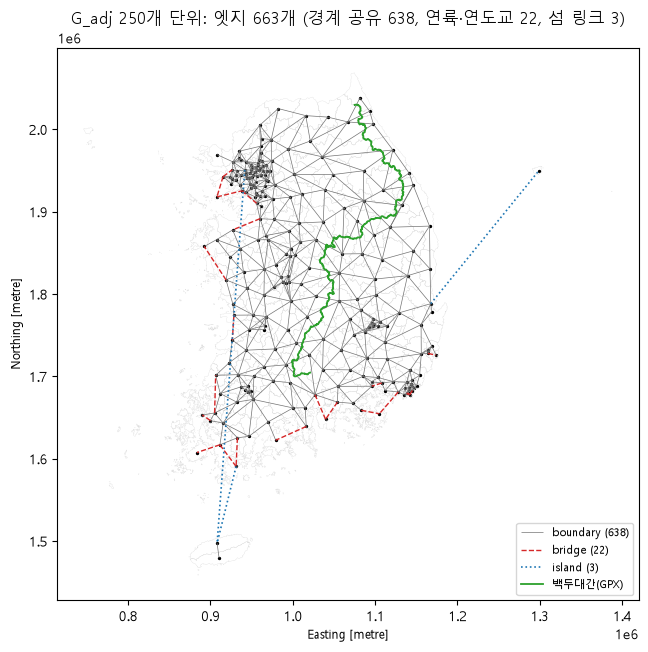

In [19]:
# 2-11. G_adj 개관 지도(확인용)
from matplotlib.collections import LineCollection

fig, ax = plt.subplots(figsize=(7.5, 9.5))
regions.boundary.plot(ax=ax, linewidth=0.15, color="0.8")
for kd_, st_, col_, lw_ in (("boundary", "-", "0.45", 0.5), ("bridge", "--", "tab:red", 1.0), ("island", ":", "tab:blue", 1.2)):
    s_ = E250[E250.kind == kd_]
    ax.add_collection(LineCollection([[XY[a], XY[b]] for a, b in zip(s_.u_idx, s_.v_idx)], colors=col_, linestyles=st_, linewidths=lw_, label=f"{kd_} ({len(s_)})"))
ax.plot(BAEKDU_LINE[:, 0], BAEKDU_LINE[:, 1], color="tab:green", linewidth=1.3, label="백두대간(GPX)")
ax.scatter(XY[:, 0], XY[:, 1], s=2, c="k")
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=8)
ax.set_title(f"G_adj 250개 단위: 엣지 {len(E250)}개 (경계 공유 {n_b}, 연륙·연도교 {n_br}, 섬 링크 {n_is})")
plt.show()

## 3. 실데이터 곡률, 검정, 보조 보고, 지도, 판정 (코드만, `RUN_REAL_CURVATURE = False`로 건너뜀)

**S3 1부에서는 이 절을 실행하지 않는다.** 2부에서 첫 코드 셀의 `RUN_REAL_CURVATURE`를 True로 바꿔 노트북을 처음부터 다시 실행한다(2절은 고정 파일과 내용이 같은지만 확인한다).
이 절의 셀은 `curvature_lib.py` 함수를 부르고 표·그림만 만든다. 1절 1-5에서 합성 장난감 나라로 같은 함수가 오류 없이 도는 것을 확인했다.

순서: 3-1 입력(고정 파일 MD5 확인) → 3-2 κ·κ_geo·κ_ex(기준, 섬 링크 ×0.5·×2) → 3-3 1항 두 검정·2항 유효성 점검·섬 링크 민감도 → 3-4 6항 보조 보고(OD 가중, 바다 비율, h_e, 산맥 선, 옆 엣지, 구조 진단)
→ 3-5 지도(κ, κ_ex, κ 하위 20개) → 3-6 κ_ex 상위 20개 5분류와 κ 하위 20개 → 3-7 판정(ADR 0013 5항).
상위 20개의 모집단은 경계 공유 엣지(검정 대상)다. 연륙·연도교와 섬 링크 엣지의 κ는 따로 보고한다.

In [20]:
# 3-1a. 입력 읽기 함수(정의만 한다)
def load_real_inputs():
    """고정된 산출물을 읽고 s3_freeze.json의 MD5와 맞는지 확인한다(다르면 멈춘다)."""
    frz = json.loads((NB_DIR / "s3_freeze.json").read_text(encoding="utf-8"))
    for nm, md in frz["outputs_md5"].items():
        assert md5_file(NB_DIR / nm) == md, f"{nm}: 고정된 파일과 다르다"
    for nm in ("travel_time.parquet", "travel_time_island_x0.5.parquet", "travel_time_island_x2.parquet", "regions.parquet", "origins.parquet"):
        assert md5_file(DATA / nm) == frz["inputs_md5"][nm], f"{nm}: 고정된 파일과 다르다"
    e250 = cl.read_edge_csv(NB_DIR / "g_adj_edges.csv")
    e249 = cl.read_edge_csv(NB_DIR / "g_adj249_edges.csv")
    reg = gpd.read_parquet(DATA / "regions.parquet")
    org = gpd.read_parquet(DATA / "origins.parquet")
    line = pd.read_parquet(DATA / "baekdudaegan_line.parquet")[["x_m", "y_m"]].to_numpy()
    n249 = int(max(e249["u_idx"].max(), e249["v_idx"].max()) + 1)
    cl.check_edge_table(e250, len(reg))
    cl.check_edge_table(e249, n249, scenarios=False, od=True)
    return {"E": e250, "n": len(reg), "sido_ids": sorted(set(e250["sido_u"]) | set(e250["sido_v"])), "xy": np.c_[org["x_m"], org["y_m"]], "boundaries": reg,
            "line": line, "E249": e249, "n249": n249, "freeze": frz}


def fmt_battery(b, label=""):
    rows = []
    for k, nm in (("main", "주 검정 ρ(κ_ex, x)"), ("partial", "편상관 ρ(κ_ex, x | r)")):
        d = b[k]
        rows.append({"검정": f"{label}{nm}", "n": d["n"], "ρ": d["rho"], "단순 p": d["p"], "jackknife 최대 p": d["p_jack"], "최대 p를 만든 시도": d["worst_sido"], "통과": d["passed"]})
    return pd.DataFrame(rows)


def fmt_p(df):
    return df.to_string(index=False, formatters={"ρ": "{:.3f}".format, "단순 p": "{:.4g}".format, "jackknife 최대 p": "{:.4g}".format})

In [21]:
# 3-1b. 입력 읽기
if RUN_REAL_CURVATURE:
    INP = load_real_inputs()
    E, N_NODES, SIDOS = INP["E"], INP["n"], INP["sido_ids"]
    print(f"입력: 엣지 {len(E)}개(경계 공유 {(E['kind'] == 'boundary').sum()}), 시도 {len(SIDOS)}개, 고정 파일 MD5 일치. 고정 시점 설정 알파 = {INP['freeze']['config']['alpha']}")
else:
    print("RUN_REAL_CURVATURE = False: 3절은 건너뛴다 (S3 1부).")

입력: 엣지 663개(경계 공유 638), 시도 17개, 고정 파일 MD5 일치. 고정 시점 설정 알파 = 0.5


In [22]:
# 3-2. κ, κ_geo, κ_ex (기준과 섬 링크 x0.5, x2)
if RUN_REAL_CURVATURE:
    RES = cl.analyze_curvature(E, N_NODES, SIDOS, alpha=INP["freeze"]["config"]["alpha"])
    bnd = (E["kind"] == "boundary").to_numpy()
    rows = []
    for sc in RES["scenarios"]:
        c = RES["cur"][sc]
        for nm, arr in (("κ", c["kappa"]), ("κ_geo", c["kappa_geo"]), ("κ_ex", c["kappa_ex"])):
            a = arr[bnd]
            rows.append({"설정": sc, "지표": nm, "경계 공유 엣지 n": int(bnd.sum()), "최소": a.min(), "25%": np.quantile(a, .25), "중앙값": np.median(a), "75%": np.quantile(a, .75), "최대": a.max(),
                         "median(d_sym/직선)": c["median_ratio"]})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    base_c = RES["cur"]["base"]
    print(f"\nκ_geo와 κ의 순위상관(경계 공유 엣지): {cl.spearman_two_sided(base_c['kappa'][bnd], base_c['kappa_geo'][bnd]):.3f}")

  설정    지표  경계 공유 엣지 n      최소     25%     중앙값    75%     최대  median(d_sym/직선)
base     κ         638 -1.9550 -0.1786 -0.0247 0.0944 0.4766            1.4352
base κ_geo         638 -2.2037 -0.1863 -0.0320 0.0893 0.4687            1.4352
base  κ_ex         638 -0.3390 -0.0439  0.0094 0.0725 0.9375            1.4352
x0.5     κ         638 -1.7800 -0.1781 -0.0230 0.0944 0.4766            1.4352
x0.5 κ_geo         638 -1.7137 -0.1823 -0.0320 0.0893 0.4687            1.4352
x0.5  κ_ex         638 -0.3390 -0.0433  0.0094 0.0724 0.5296            1.4352
  x2     κ         638 -3.4940 -0.1789 -0.0247 0.0944 0.4766            1.4352
  x2 κ_geo         638 -3.8862 -0.1863 -0.0320 0.0893 0.4687            1.4352
  x2  κ_ex         638 -0.3390 -0.0439  0.0094 0.0730 1.8131            1.4352

κ_geo와 κ의 순위상관(경계 공유 엣지): 0.895


In [23]:
# 3-3. 1항 두 검정, 2항 유효성 점검, 섬 링크 민감도
if RUN_REAL_CURVATURE:
    print("[1항 검정] x = 경사 s (m/km), 단측(H1: ρ > 0), 대상 경계 공유 엣지, 균등 이웃 분포")
    print(fmt_p(fmt_battery(RES["battery"])))
    print("\n[2항 유효성 점검] κ_ex와의 Spearman ρ (|ρ| < 0.1이어야 통과)")
    vr = RES["validity"]
    print(pd.DataFrame({"변수": list(vr["rho"]), "ρ": list(vr["rho"].values())}).to_string(index=False, float_format=lambda v: f"{v:.3f}"), "\n통과:", vr["ok"])
    print(f"κ와 (1/deg_u + 1/deg_v)의 Spearman ρ = {RES['structure']['kappa']['1/deg_u+1/deg_v']:.3f} (보고용)")
    print("\n[섬 링크 민감도] 섬 링크 시간(소요 + 대기)을 x0.5, x2로 바꿔 다시 계산")
    rows = []
    for sc, b in [("base", RES["battery"])] + list(RES["island_battery"].items()):
        rows.append({"설정": sc, "주 검정 통과": b["main"]["passed"], "편상관 통과": b["partial"]["passed"], "주 p": b["main"]["p"], "주 jackknife p": b["main"]["p_jack"],
                     "편 p": b["partial"]["p"], "편 jackknife p": b["partial"]["p_jack"]})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    flips = [sc for sc in RES["island_battery"] if tuple(RES["island_pass"][sc]) != tuple(RES["island_pass"]["base"])]
    print("통과 여부가 뒤집힌 설정:", flips or "없음")
    print(f"\n[1단계 점검] 분/km(= r)와 경사 s의 단측 Spearman: ρ = {RES['stage1']['rho']:.3f}, p = {RES['stage1']['p']:.4g}")
    print(f"[우회율 비교] ρ(κ_ex, 분/km) = {RES['rho_kex_r']:.3f}")

[1항 검정] x = 경사 s (m/km), 단측(H1: ρ > 0), 대상 경계 공유 엣지, 균등 이웃 분포
                검정   n      ρ     단순 p jackknife 최대 p 최대 p를 만든 시도    통과
   주 검정 ρ(κ_ex, x) 638  0.102 0.004841        0.03505          41  True
편상관 ρ(κ_ex, x | r) 638 -0.011   0.6139         0.9626          11 False

[2항 유효성 점검] κ_ex와의 Spearman ρ (|ρ| < 0.1이어야 통과)
             변수      ρ
1/deg_u+1/deg_v  0.227
     해안·접경 지시변수  0.028
      log 직선 거리 -0.207 
통과: False
κ와 (1/deg_u + 1/deg_v)의 Spearman ρ = 0.202 (보고용)

[섬 링크 민감도] 섬 링크 시간(소요 + 대기)을 x0.5, x2로 바꿔 다시 계산
  설정  주 검정 통과  편상관 통과      주 p  주 jackknife p    편 p  편 jackknife p
base     True   False 0.004841        0.03505 0.6139         0.9626
x0.5     True   False 0.004472        0.03358 0.5963         0.9621
  x2     True   False 0.005318        0.03689 0.6331         0.9624
통과 여부가 뒤집힌 설정: 없음

[1단계 점검] 분/km(= r)와 경사 s의 단측 Spearman: ρ = 0.132, p = 0.0003982
[우회율 비교] ρ(κ_ex, 분/km) = 0.822


In [24]:
# 3-4. 6항 보조 보고 (5항이 정한 곳 밖에서는 판정에 쓰지 않는다)
if RUN_REAL_CURVATURE:
    print("[바다 비율] 보간 전 바다·자료 없음 표본이 50%를 넘는 경계 공유 엣지:", RES["n_sea_over_half"], "개 -> 뺀 1항 두 검정")
    print(fmt_p(fmt_battery(RES["sea_excluded"])))
    print("\n[h_e로 바꾼 1항 검정] x = 초과 고도 h_e")
    print(fmt_p(fmt_battery(RES["h_e"])))
    print("\n[산맥 선 교차 지시변수로 바꾼 1항 검정] x = b_e (백두대간 선)")
    print(fmt_p(fmt_battery(RES["barrier_baekdu"])))
    if "barrier_sens" in RES:
        print("\n[민감도 선(백두대간 + OSM 정맥)] x = b_e")
        print(fmt_p(fmt_battery(RES["barrier_sens"])))
    se = RES["side_edges"]
    print(f"\n[옆 엣지] 백두대간 선과 교차하는 경계 공유 엣지 {se['n_barrier']}개, 끝점을 공유하는 옆 엣지 {se['n_side']}개: 평균 κ_ex 교차 {se['mean_kex_barrier']:.4f}, "
          f"옆 엣지 {se['mean_kex_side']:.4f}(음수 예상), 나머지 {se['mean_kex_other']:.4f}")
    st = RES["structure"]
    print("\n[구조 진단] Spearman ρ")
    print(pd.DataFrame({"κ": st["kappa"], "κ_ex": st["kappa_ex"]}).to_string(float_format=lambda v: f"{v:.3f}"))
    t20 = RES["top20"]
    print(f"\n[상위 20개의 해안·접경 비율] {t20['coastal_ratio']:.2f} (경계 공유 엣지 전체 {t20['coastal_ratio_all']:.2f})")
    hh = t20["h_e_hyper"]
    print(f"[h_e 상위 10%를 자연 장벽으로 본 상위 20개 중 n/20] {hh['hit']}/{hh['k']}, 기저율 10%({hh['K']}/{hh['N']})에서 단측 초기하 p = {hh['p']:.4g}")
    nbk = RES["non_boundary_kappa"]
    if nbk is not None:
        print("\n[연륙·연도교와 섬 링크 엣지의 κ] (검정에서 뺀 엣지)")
        print(nbk.round(4).to_string(index=False))
    # OD 가중: 249개 단위 그래프에서 따로 구한다
    OD_OK = False
    try:
        E249 = INP["E249"]
        RES249 = cl.analyze_curvature(E249, INP["n249"], SIDOS, scenario_cols=(), alpha=INP["freeze"]["config"]["alpha"], weight=E249["w_od"].to_numpy())
        OD_OK = True
        print("\n[통근·통학 OD 가중, 249개 단위 그래프] 이웃 가중치 T_xz + T_zx, κ_geo도 같은 관측 가중. 시도 경계 효과와 겹친다(흐름은 시도 경계에서 줄어듦).")
        print(fmt_p(fmt_battery(RES249["battery"])))
        print("유효성 점검 ρ:", {k: round(v, 3) for k, v in RES249["validity"]["rho"].items()}, "통과:", RES249["validity"]["ok"])
        print(f"1단계 점검(249): ρ = {RES249['stage1']['rho']:.3f}, p = {RES249['stage1']['p']:.4g}")
    except Exception as exc:  # 계산하지 못하면 5항 4)의 "OD 가중을 계산하지 못함"
        print("OD 가중 계산 실패:", repr(exc))

[바다 비율] 보간 전 바다·자료 없음 표본이 50%를 넘는 경계 공유 엣지: 1 개 -> 뺀 1항 두 검정
                검정   n      ρ    단순 p jackknife 최대 p 최대 p를 만든 시도    통과
   주 검정 ρ(κ_ex, x) 637  0.100 0.00576        0.04065          41  True
편상관 ρ(κ_ex, x | r) 637 -0.015  0.6482         0.9709          11 False

[h_e로 바꾼 1항 검정] x = 초과 고도 h_e
                검정   n      ρ   단순 p jackknife 최대 p 최대 p를 만든 시도    통과
   주 검정 ρ(κ_ex, x) 638 -0.110 0.9972         0.9992          26 False
편상관 ρ(κ_ex, x | r) 638 -0.039 0.8356          0.991          11 False

[산맥 선 교차 지시변수로 바꾼 1항 검정] x = b_e (백두대간 선)
                검정   n      ρ    단순 p jackknife 최대 p 최대 p를 만든 시도    통과
   주 검정 ρ(κ_ex, x) 638  0.057 0.07561         0.2872          51 False
편상관 ρ(κ_ex, x | r) 638 -0.010  0.5994         0.8317          47 False

[민감도 선(백두대간 + OSM 정맥)] x = b_e
                검정   n      ρ   단순 p jackknife 최대 p 최대 p를 만든 시도    통과
   주 검정 ρ(κ_ex, x) 638 -0.012 0.6218         0.8619          47 False
편상관 ρ(κ_ex, x | r) 638  0.075 0.0291         0.2166      

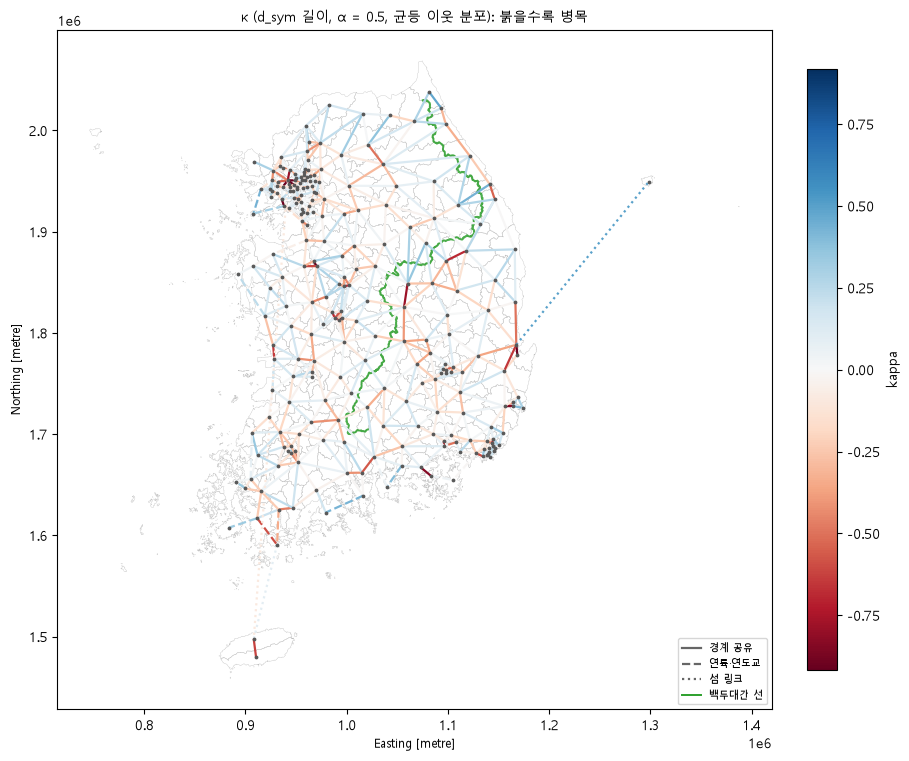

C:\dev\kfm-spike\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


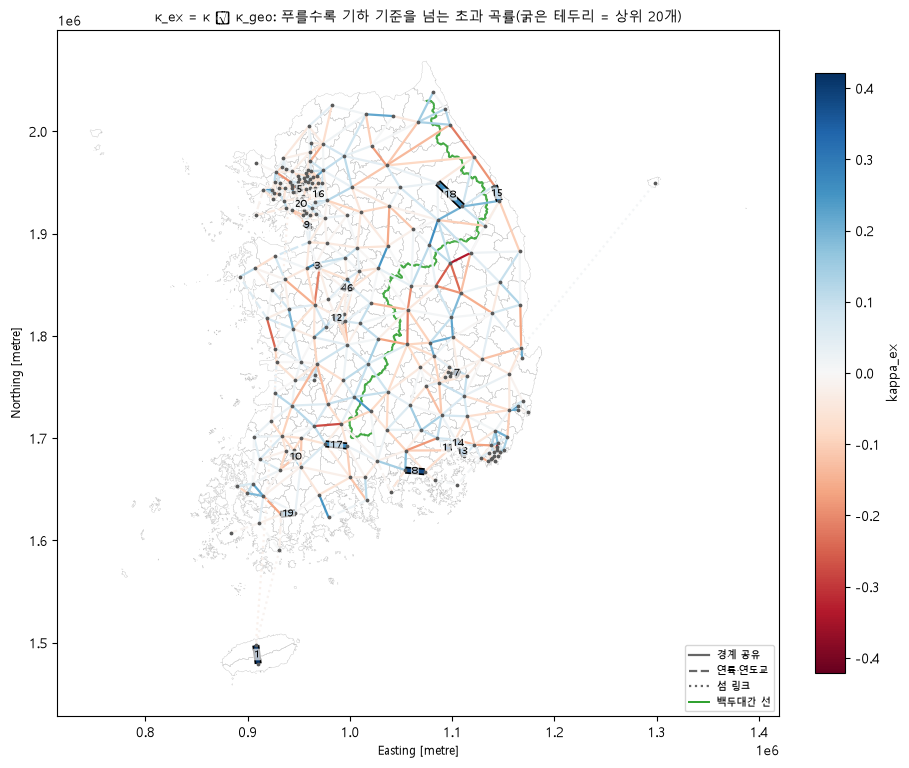

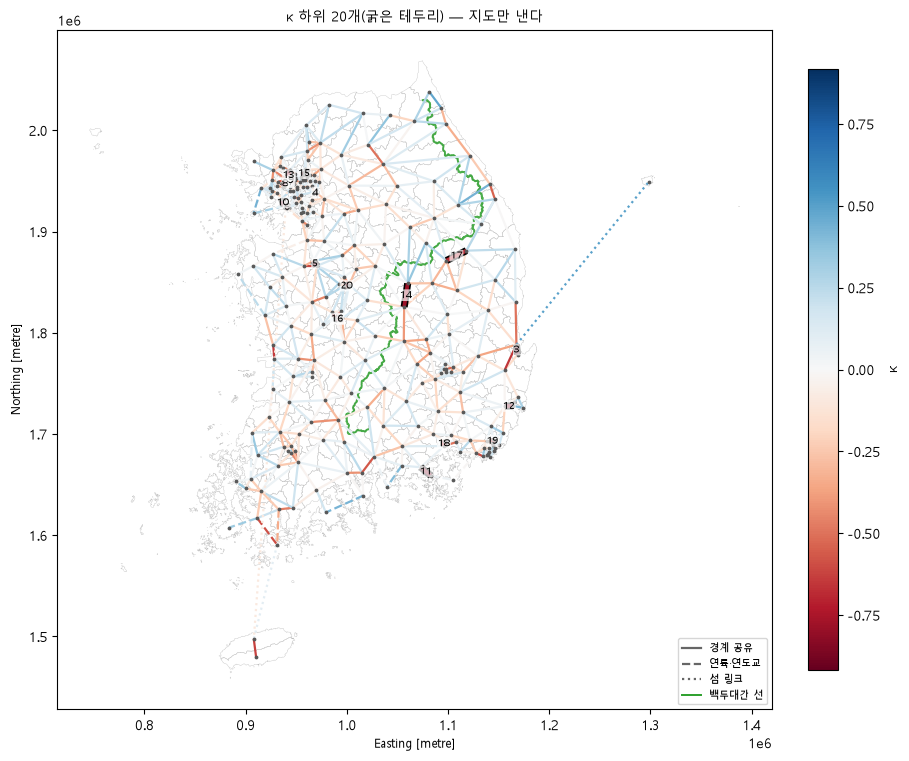

In [25]:
# 3-5. 지도: κ, κ_ex, κ 하위 20개
if RUN_REAL_CURVATURE:
    plt.rcParams["font.family"] = "Malgun Gothic"
    u, v = E["u_idx"].to_numpy(), E["v_idx"].to_numpy()
    kind = E["kind"].to_numpy()
    for key, ttl, hl in (("kappa", "κ (d_sym 길이, α = 0.5, 균등 이웃 분포): 붉을수록 병목", None),
                         ("kappa_ex", "κ_ex = κ − κ_geo: 푸를수록 기하 기준을 넘는 초과 곡률(굵은 테두리 = 상위 20개)", RES["top20"]["edge_pos"])):
        fig, ax = plt.subplots(figsize=(9, 11), constrained_layout=True)
        ann = [(p, str(i + 1)) for i, p in enumerate(RES["top20"]["edge_pos"])] if hl is not None else None
        vmax = float(np.quantile(np.abs(RES["cur"]["base"][key][bnd]), 0.99))  # 색 범위는 경계 공유 엣지 기준(섬 링크 극단값이 색을 누르지 않게)
        cl.plot_edge_map(ax, INP["boundaries"], INP["xy"], u, v, RES["cur"]["base"][key], kind=kind, highlight=hl, line=INP["line"], title=ttl, label=key, annotate=ann, vmax=vmax)
        plt.show()
    fig, ax = plt.subplots(figsize=(9, 11), constrained_layout=True)
    cl.plot_edge_map(ax, INP["boundaries"], INP["xy"], u, v, RES["cur"]["base"]["kappa"], kind=kind, highlight=RES["bottom20_kappa_pos"], line=INP["line"],
                     title="κ 하위 20개(굵은 테두리) — 지도만 낸다", label="κ", annotate=[(p, str(i + 1)) for i, p in enumerate(RES["bottom20_kappa_pos"])],
                     vmax=float(np.quantile(np.abs(RES["cur"]["base"]["kappa"][bnd]), 0.99)))
    plt.show()

In [26]:
# 3-6. κ_ex 상위 20개와 PLAN 6.1a 5분류, κ 하위 20개
if RUN_REAL_CURVATURE:
    t20 = RES["top20"]
    pos = t20["edge_pos"]
    top_tbl = pd.DataFrame({"순위": np.arange(1, 21), "지역 u": E["u_name"].to_numpy()[pos], "지역 v": E["v_name"].to_numpy()[pos], "κ_ex": t20["kappa_ex"], "κ": RES["cur"]["base"]["kappa"][pos],
                            "s(m/km)": E["s"].to_numpy()[pos], "r(분/km)": E["r"].to_numpy()[pos], "h_e(m)": E["h_e"].to_numpy()[pos], "바다 비율": E["sea_frac"].to_numpy()[pos],
                            "섬 링크에 좌우": t20["island_sensitive"], "분류": t20["label"]})
    print(top_tbl.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    print("\n분류별 개수:", t20["n_each"], "| 자연 장벽 n/20 =", t20["n_barrier"], "| 데이터·설정 문제 =", t20["n_data_problem"], f"| 기준 20위 κ_ex = {t20['threshold_20th']:.4f}")
    pos_b = RES["bottom20_kappa_pos"]
    print("\nκ 하위 20개(지도 설명용):")
    print(pd.DataFrame({"순위": np.arange(1, 21), "지역 u": E["u_name"].to_numpy()[pos_b], "지역 v": E["v_name"].to_numpy()[pos_b], "κ": RES["cur"]["base"]["kappa"][pos_b],
                        "κ_ex": RES["cur"]["base"]["kappa_ex"][pos_b]}).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

 순위           지역 u           지역 v  κ_ex      κ  s(m/km)  r(분/km)   h_e(m)  바다 비율  섬 링크에 좌우   분류
  1    제주특별자치도 제주시   제주특별자치도 서귀포시 0.938 -0.623   81.773    2.478 1271.667  0.000     False 망 단절
  2    경기도 안양시 동안구        경기도 의왕시 0.530 -0.248   59.472    2.696  206.605  0.000     False 망 단절
  3   충청남도 천안시 동남구   충청남도 천안시 서북구 0.478 -1.236    7.194    1.513   11.254  0.000     False   기타
  4   충청북도 청주시 서원구   충청북도 청주시 흥덕구 0.471 -0.346   21.197    1.831    6.303  0.000     False 망 단절
  5      서울특별시 동작구      서울특별시 관악구 0.458 -0.464   28.145    2.078   25.443  0.000     False 망 단절
  6   충청북도 청주시 상당구   충청북도 청주시 서원구 0.448 -0.686   12.084    1.946    0.000  0.000     False 망 단절
  7       대구광역시 동구      대구광역시 수성구 0.442 -0.384   28.257    2.010   22.231  0.000     False 망 단절
  8       경상남도 사천시       경상남도 고성군 0.387  0.109   81.630    2.604  215.925  0.000     False 망 단절
  9        경기도 오산시        경기도 화성시 0.371 -0.423   31.377    1.908   94.204  0.000     False 망 단절
 10       광주광역시 동구       광주광역시 남구 0.338 

In [27]:
# 3-7. 0S 곡률 판정 (ADR 0013 5항)
if RUN_REAL_CURVATURE:
    od_main = None
    if OD_OK:
        od_main = {"p": RES249["battery"]["main"]["p"], "p_jack": RES249["battery"]["main"]["p_jack"]}
    DEC = cl.decide_0s(**RES["decision_inputs"], od_main=od_main)
    di = RES["decision_inputs"]
    print("판정에 쓴 수치")
    print(f"  유효성 점검 통과: {di['validity_ok']} | 상위 20개 중 데이터·설정 문제: {di['n_data_problem_top20']}개 | 섬 링크 민감도 통과 여부(주, 편): {di['island_pass']}")
    print(f"  주 검정 p = {di['main']['p']:.4g}, jackknife p = {di['main']['p_jack']:.4g} | 편상관 p = {di['partial']['p']:.4g}, jackknife p = {di['partial']['p_jack']:.4g}")
    print(f"  OD 가중 주 검정: {od_main} | 1단계 점검: {di['stage1']}")
    print(f"\n판정: {DEC['label']} — {DEC['detail']}")

판정에 쓴 수치
  유효성 점검 통과: False | 상위 20개 중 데이터·설정 문제: 0개 | 섬 링크 민감도 통과 여부(주, 편): {'base': (True, False), 'x0.5': (True, False), 'x2': (True, False)}
  주 검정 p = 0.004841, jackknife p = 0.03505 | 편상관 p = 0.6139, jackknife p = 0.9626
  OD 가중 주 검정: {'p': 4.273743976542257e-06, 'p_jack': 0.00024846400028420766} | 1단계 점검: {'rho': 0.13246119268460213, 'p': 0.0003982306411995782}

판정: 조정 — 유효성 점검 실패
